# Do sinal ao espectro: um analisador e filtro de sinais

**Sistematização — Métodos Matemáticos**
Séries de Fourier → Transformada de Fourier → Transformada de Laplace

**Autora:** Isabella Campos Bueno

**Data:** 10 de outubro de 2026

**Resumo.** A ideia deste trabalho foi pegar um som de verdade, uma nota de violão, e acompanhar o que a disciplina tem a dizer sobre ele do começo ao fim. Comecei pelo caso de livro: montar uma onda quadrada somando senos, e ver de perto o fenômeno de Gibbs. Depois fiz o caminho contrário, usando a FFT para descobrir quais senos existem dentro de um Lá4 de violão. Na terceira parte sujei essa gravação de propósito, com zumbido de 60 Hz e chiado, e tentei limpá-la com um filtro simples. Por último olhei para esse mesmo filtro como um circuito, com equação diferencial, função de transferência $H(s)$, polos e zeros, e mostro que o desenho dos polos e zeros conta exatamente o que eu tinha visto no espectro.

**Índice**

1. [Etapa 1 — Aproximando funções com ondas](#etapa1) (Séries de Fourier, Gibbs, Parseval)
2. [Etapa 2 — Do tempo para a frequência](#etapa2) (FFT, harmônicos, Nyquist e aliasing)
3. [Etapa 3 — Filtrar e reconstruir](#etapa3) (contaminação controlada, notch, transformada inversa, SNR)
4. [Etapa 4 — O filtro como sistema linear](#etapa4) (Laplace, $H(s)$, polos e zeros, Bode, fechamento)
5. [Conclusão](#conclusao)

## Preparação do ambiente

Importações, caminhos relativos, semente fixa e funções auxiliares de figura usadas em todo o notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp
from scipy import fft, signal, special
from scipy.io import wavfile
from IPython.display import Audio, Math, display

# Caminhos relativos: funciona rodando da raiz do repositório ou de notebooks/
RAIZ = Path(".") if Path("data").exists() else Path("..")
DIR_FIG = RAIZ / "outputs" / "figures"
DIR_AUDIO = RAIZ / "outputs" / "audio"
ARQ_AUDIO = RAIZ / "data" / "la4_violao.wav"
for pasta in (DIR_FIG, DIR_AUDIO):
    pasta.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(42)   # semente fixa: o ruído gerado é sempre o mesmo
F_NOTA = 440.0                    # Hz, frequência teórica do Lá4 (afinação padrão)

# Cores fixas para as três versões do sinal, usadas em todas as figuras
COR = {"original": "#1f77b4", "ruidoso": "#d62728", "filtrado": "#2ca02c", "filtro": "#111111"}

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.titlesize": 11, "font.size": 10})
pd.set_option("display.precision", 4)
sp.init_printing()

In [2]:
def salvar_fig(fig, nome):
    """Ajusta o layout, salva a figura em outputs/figures (PNG, 200 dpi) e a exibe."""
    fig.tight_layout()
    fig.savefig(DIR_FIG / nome, bbox_inches="tight")
    plt.show()


def em_db(valor, ref=1.0):
    """Converte amplitude em decibéis relativos a `ref` (com piso para evitar log de zero)."""
    return 20 * np.log10(np.maximum(np.abs(valor), 1e-15) / ref)

<a id="etapa1"></a>
# Etapa 1 — Aproximando funções com ondas

## 1.1 A onda quadrada e a série de Fourier

Trabalho com a onda quadrada ímpar de período $T$, com saltos entre $-1$ e $+1$:

$$
f(t)=\begin{cases}-1, & -T/2<t<0\\ +1, & 0<t<T/2\end{cases}\qquad f(t+T)=f(t).
$$

Com $\omega_0 = 2\pi/T$, a série de Fourier na **forma trigonométrica** é

$$
f(t)\sim\frac{a_0}{2}+\sum_{n=1}^{\infty}\big[a_n\cos(n\omega_0 t)+b_n\sin(n\omega_0 t)\big],
\qquad
a_n=\frac{2}{T}\int_{-T/2}^{T/2}f(t)\cos(n\omega_0 t)\,dt,\quad
b_n=\frac{2}{T}\int_{-T/2}^{T/2}f(t)\sin(n\omega_0 t)\,dt,
$$

e na **forma complexa**

$$
f(t)\sim\sum_{n=-\infty}^{\infty}c_n\,e^{i n\omega_0 t},\qquad
c_n=\frac{1}{T}\int_{-T/2}^{T/2}f(t)\,e^{-i n\omega_0 t}\,dt .
$$

A seguir o `sympy` faz essas integrais simbolicamente, e eu confiro o resultado com a fórmula fechada conhecida.

In [3]:
t, T = sp.symbols("t T", real=True, positive=True)
n = sp.symbols("n", integer=True, positive=True)
omega0 = 2 * sp.pi / T


def integrar_no_periodo(g):
    """Calcula ∫ f(t)·g(t) dt em um período, com f = -1 em (-T/2, 0) e f = +1 em (0, T/2)."""
    return sp.integrate(-g, (t, -T / 2, 0)) + sp.integrate(g, (t, 0, T / 2))


a0 = sp.simplify(2 / T * integrar_no_periodo(sp.Integer(1)))
an = sp.simplify(2 / T * integrar_no_periodo(sp.cos(n * omega0 * t)))
bn = sp.simplify(2 / T * integrar_no_periodo(sp.sin(n * omega0 * t)))
cn = sp.simplify(1 / T * integrar_no_periodo(sp.exp(-sp.I * n * omega0 * t)))

display(Math(r"a_0 = " + sp.latex(a0) + r",\qquad a_n = " + sp.latex(an)))
display(Math(r"b_n = " + sp.latex(bn)))
display(Math(r"c_n = " + sp.latex(sp.simplify(cn.rewrite(sp.cos)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [4]:
# Conferência com a fórmula fechada e com a relação entre as duas formas
tabela_coef = pd.DataFrame({
    "n": range(1, 8),
    "b_n (sympy)": [bn.subs(n, k) for k in range(1, 8)],
    "4/(nπ) se n ímpar, 0 se par": [sp.Rational(4, k) / sp.pi if k % 2 else sp.Integer(0) for k in range(1, 8)],
    "c_n (sympy)": [sp.simplify(cn.subs(n, k)) for k in range(1, 8)],
})
tabela_coef["b_n confere?"] = [sp.simplify(a - b) == 0 for a, b in
                               zip(tabela_coef.iloc[:, 1], tabela_coef.iloc[:, 2])]
display(tabela_coef)

diferenca = sp.simplify(cn - (an - sp.I * bn) / 2)
print("c_n - (a_n - i·b_n)/2 =", diferenca, " -> relação entre as formas verificada:", diferenca == 0)

,n,b_n (sympy),"4/(nπ) se n ímpar, 0 se par",c_n (sympy),b_n confere?
0,1,4/pi,4/pi,-2*I/pi,True
1,2,0,0,0,True
2,3,4/(3*pi),4/(3*pi),-2*I/(3*pi),True
3,4,0,0,0,True
4,5,4/(5*pi),4/(5*pi),-2*I/(5*pi),True
5,6,0,0,0,True
6,7,4/(7*pi),4/(7*pi),-2*I/(7*pi),True


c_n - (a_n - i·b_n)/2 = 0  -> relação entre as formas verificada: True


O resultado do `sympy` bate com o que se espera olhando para o desenho da onda.

Não sobrou nenhum cosseno nem termo constante ($a_0=0$ e $a_n=0$). Faz sentido: a onda é ímpar e tem média zero, e cosseno é uma função par, então não tem como ele ajudar a construí-la.

Para os senos saiu $b_n = \dfrac{2\,(1-(-1)^n)}{n\pi}$. Essa expressão vale $\dfrac{4}{n\pi}$ quando $n$ é ímpar e zero quando $n$ é par, que é exatamente a fórmula fechada do enunciado. A tabela confere isso termo a termo. Os harmônicos pares somem por causa de outra simetria da onda: meio período depois ela vale o oposto, $f(t+T/2) = -f(t)$.

A série fica então

$$f(t)\sim \frac{4}{\pi}\left[\sin\omega_0 t+\frac{\sin 3\omega_0 t}{3}+\frac{\sin 5\omega_0 t}{5}+\dots\right].$$

Repare que as amplitudes caem só como $1/n$, o que é bem devagar. Esse decaimento lento é típico de função com salto, e vai cobrar seu preço daqui a pouco, no fenômeno de Gibbs.

Na forma complexa, o `sympy` confirmou a relação $c_n = \dfrac{a_n - i\,b_n}{2}$ para $n>0$ (e, como $f$ é real, $c_{-n} = \overline{c_n}$). Aqui dá $c_n = -\dfrac{2i}{n\pi}$ para $n$ ímpar. O fato de ser imaginário puro é só outro jeito de dizer "só tem seno". As duas formas guardam a mesma informação; prefiro a complexa nas próximas etapas porque ela junta amplitude e fase em um número só, e é ela que vira a Transformada de Fourier.

## 1.2 Ortogonalidade das funções base

Os coeficientes podem ser calculados um de cada vez porque as funções $\{1,\cos(n\omega_0 t),\sin(n\omega_0 t)\}$ são **ortogonais** no período, com o produto interno

$$\langle g,h\rangle=\int_0^T g(t)\,h(t)\,dt .$$

Abaixo monto numericamente a matriz de todos os produtos internos entre as primeiras funções base (matriz de Gram).

In [5]:
def funcoes_base(t_grade, T_periodo, n_max):
    """Devolve os nomes e os valores de {1, cos(nω0t), sin(nω0t)} para n = 1..n_max."""
    w = 2 * np.pi / T_periodo
    nomes, valores = ["1"], [np.ones_like(t_grade)]
    for k in range(1, n_max + 1):
        nomes += [f"cos {k}ω₀t", f"sin {k}ω₀t"]
        valores += [np.cos(k * w * t_grade), np.sin(k * w * t_grade)]
    return nomes, np.array(valores)


def matriz_de_gram(valores, dt):
    """Produtos internos ⟨g, h⟩ = ∫ g·h dt aproximados por soma de Riemann em um período."""
    return valores @ valores.T * dt


T_NUM = 1.0                                             # período usado nos exemplos numéricos (s)
t_grade = np.linspace(0, T_NUM, 4000, endpoint=False)   # um período, sem repetir o extremo
nomes_base, valores_base = funcoes_base(t_grade, T_NUM, n_max=4)
gram = matriz_de_gram(valores_base, t_grade[1] - t_grade[0])

fora_diag = gram - np.diag(np.diag(gram))
print(f"Diagonal: {np.round(np.diag(gram), 6)}")
print(f"Maior |valor| fora da diagonal: {np.abs(fora_diag).max():.2e}")

Diagonal: [1.  0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5]
Maior |valor| fora da diagonal: 8.42e-17


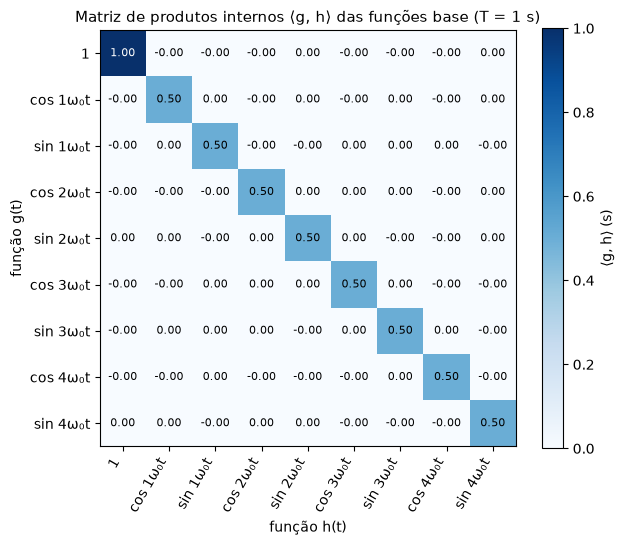

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(gram, cmap="Blues", vmin=0, vmax=T_NUM)
ax.set_xticks(range(len(nomes_base)), nomes_base, rotation=60, ha="right")
ax.set_yticks(range(len(nomes_base)), nomes_base)
for i in range(len(nomes_base)):
    for j in range(len(nomes_base)):
        ax.text(j, i, f"{gram[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if gram[i, j] > 0.6 else "black")
ax.set_title("Matriz de produtos internos ⟨g, h⟩ das funções base (T = 1 s)")
ax.set_xlabel("função h(t)")
ax.set_ylabel("função g(t)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="⟨g, h⟩ (s)")
salvar_fig(fig, "fig01_ortogonalidade.png")

A matriz saiu diagonal, como a teoria promete. O produto interno entre duas funções base *diferentes* deu zero (o maior valor fora da diagonal é da ordem de $10^{-16}$, ou seja, só arredondamento do computador). Na diagonal aparece $T$ para a função constante e $T/2$ para cada seno e cosseno.

É por causa disso que dá para calcular os coeficientes um de cada vez. Se eu pego a série inteira, multiplico por $\sin(m\omega_0 t)$ e integro no período, todos os termos morrem menos um:

$$
\int_0^T f(t)\sin(m\omega_0 t)\,dt=\sum_n b_n\underbrace{\int_0^T\sin(n\omega_0 t)\sin(m\omega_0 t)\,dt}_{=\,T/2\ \text{se}\ n=m,\ \ 0\ \text{caso contrário}}=b_m\frac{T}{2}
\;\;\Longrightarrow\;\; b_m=\frac{2}{T}\int_0^T f(t)\sin(m\omega_0 t)\,dt .
$$

A imagem que me ajudou a entender é a de vetores: é como projetar um vetor em eixos perpendiculares. Cada coeficiente é a "sombra" de $f$ em cima de uma função base, e como os eixos são perpendiculares, uma sombra não atrapalha a outra. O fator $2/T$ que aparece em todas as fórmulas dos coeficientes também deixa de ser misterioso: é o inverso do $T/2$ que está na diagonal.

## 1.3 Somas parciais

A soma parcial com harmônicos até a ordem $N$ é

$$S_N(t)=\frac{4}{\pi}\sum_{\substack{n=1\\ n\ \text{ímpar}}}^{N}\frac{\sin(n\omega_0 t)}{n}.$$

**Convenção:** $N$ é a ordem do maior harmônico incluído. Como os harmônicos pares são nulos, $N=101$ corresponde a 51 senos de fato somados.

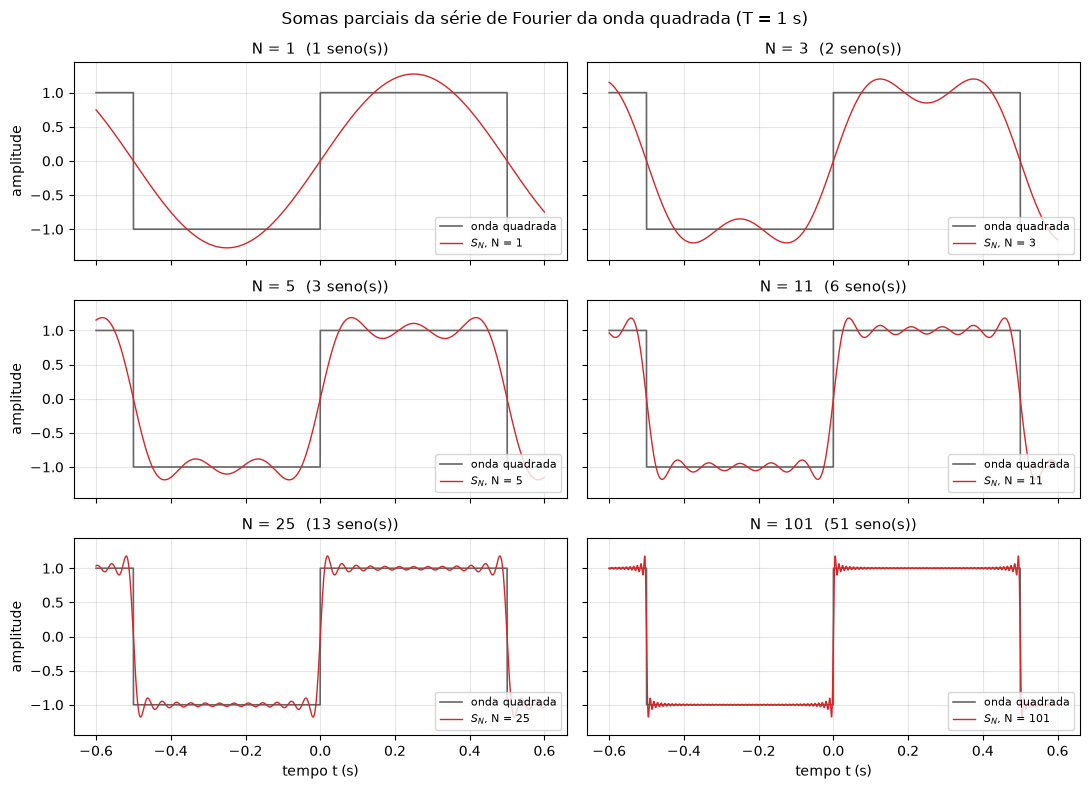

In [7]:
def onda_quadrada(t_grade, T_periodo=1.0):
    """Onda quadrada ímpar de período T: +1 na primeira metade do período, -1 na segunda."""
    return np.where((t_grade / T_periodo) % 1.0 < 0.5, 1.0, -1.0)


def soma_parcial(t_grade, N, T_periodo=1.0):
    """Soma parcial S_N(t) da série da onda quadrada (harmônicos ímpares até a ordem N)."""
    ordens = np.arange(1, N + 1, 2)
    senos = np.sin(2 * np.pi * np.outer(ordens, t_grade) / T_periodo)
    return (4 / np.pi) * (senos / ordens[:, None]).sum(axis=0)


LISTA_N = [1, 3, 5, 11, 25, 101]
t_plot = np.linspace(-0.6, 0.6, 6001)

fig, eixos = plt.subplots(3, 2, figsize=(11, 8), sharex=True, sharey=True)
for ax, N in zip(eixos.ravel(), LISTA_N):
    ax.plot(t_plot, onda_quadrada(t_plot), color="0.4", lw=1.2, label="onda quadrada")
    ax.plot(t_plot, soma_parcial(t_plot, N), color=COR["ruidoso"], lw=1.0, label=f"$S_N$, N = {N}")
    ax.set_title(f"N = {N}  ({(N + 1) // 2} seno(s))")
    ax.set_ylim(-1.45, 1.45)
    ax.legend(loc="lower right", fontsize=8)
for ax in eixos[-1]:
    ax.set_xlabel("tempo t (s)")
for ax in eixos[:, 0]:
    ax.set_ylabel("amplitude")
fig.suptitle("Somas parciais da série de Fourier da onda quadrada (T = 1 s)")
salvar_fig(fig, "fig02_somas_parciais.png")

Com $N=1$ há um seno só, que acerta o período e o sinal da onda e mais nada. A cada harmônico que entra, os patamares ficam mais retos e as subidas mais íngremes. Dá para pensar assim: os harmônicos baixos dão o formato geral e os altos vão esculpindo as quinas. Nos trechos planos a melhora é contínua, com a ondulação ficando cada vez menor e mais rápida.

Perto dos saltos a história é outra. Ali aparece um pico que passa de $1$, e o que me chamou a atenção é que ele **não diminui** de $N=11$ para $N=101$: ele só chega mais perto do salto. Já no ponto exato do salto ($t=0$) todas as somas passam por $0$, que é a média entre $-1$ e $+1$, como diz o teorema de Dirichlet.

Esse pico teimoso é o fenômeno de Gibbs, e na próxima seção vou medi-lo.

## 1.4 Fenômeno de Gibbs

Meço o valor máximo de $S_N(t)$ logo à direita do salto em $t=0$ para vários $N$. A teoria prevê que o máximo tende a

$$\lim_{N\to\infty}\max_t S_N(t)=\frac{2}{\pi}\,\mathrm{Si}(\pi)=\frac{2}{\pi}\int_0^{\pi}\frac{\sin u}{u}\,du\approx 1{,}17898,$$

isto é, um excesso de cerca de $0{,}179$, que é $\approx 8{,}95\%$ do salto total (que vale $2$).

In [8]:
def medir_gibbs(N, T_periodo=1.0, pontos=4001):
    """Localiza o primeiro máximo de S_N à direita do salto. Retorna (t_pico, valor_pico)."""
    # O primeiro máximo fica em t = T/(2(N+1)); a grade fina cobre até o dobro disso
    t_fino = np.linspace(0, T_periodo / (N + 1), pontos)[1:]
    s = soma_parcial(t_fino, N, T_periodo)
    i = np.argmax(s)
    return t_fino[i], s[i]


LIMITE_GIBBS = 2 / np.pi * special.sici(np.pi)[0]
SALTO = 2.0

linhas = []
for N in [1, 3, 5, 11, 25, 101, 501, 2001]:
    t_pico, pico = medir_gibbs(N)
    linhas.append({"N": N, "valor do pico": pico, "excesso (pico - 1)": pico - 1,
                   "excesso (% do salto)": 100 * (pico - 1) / SALTO,
                   "posição do pico t/T": t_pico / T_NUM})
tabela_gibbs = pd.DataFrame(linhas)
print(f"Limite teórico: pico = {LIMITE_GIBBS:.5f}  ->  excesso = "
      f"{100 * (LIMITE_GIBBS - 1) / SALTO:.3f}% do salto")
display(tabela_gibbs)

Limite teórico: pico = 1.17898  ->  excesso = 8.949% do salto


,N,valor do pico,excesso (pico - 1),excesso (% do salto),posição do pico t/T
0,1,1.2732,0.2732,13.6620,0.2500
1,3,1.2004,0.2004,10.0211,0.1250
2,5,1.1884,0.1884,9.4178,0.0833
3,11,1.1813,0.1813,9.0651,0.0417
4,25,1.1795,0.1795,8.9737,0.0192
5,101,1.1790,0.1790,8.9506,0.0049
6,501,1.1790,0.1790,8.9491,0.0010
7,2001,1.1790,0.1790,8.9490,0.0002


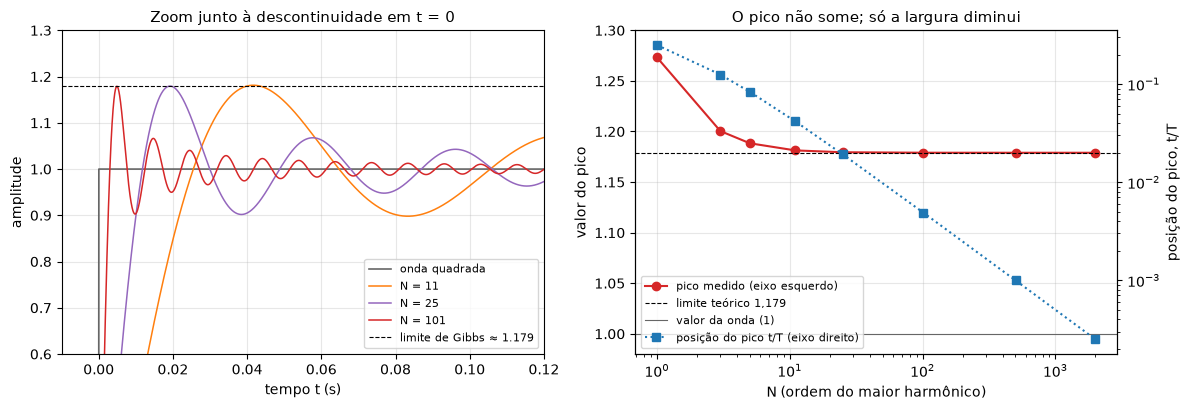

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

t_zoom = np.linspace(-0.01, 0.12, 6001)
ax1.plot(t_zoom, onda_quadrada(t_zoom), color="0.4", lw=1.2, label="onda quadrada")
for N, cor in zip([11, 25, 101], ["#ff7f0e", "#9467bd", COR["ruidoso"]]):
    ax1.plot(t_zoom, soma_parcial(t_zoom, N), color=cor, lw=1.1, label=f"N = {N}")
ax1.axhline(LIMITE_GIBBS, color="k", ls="--", lw=0.8, label=f"limite de Gibbs ≈ {LIMITE_GIBBS:.3f}")
ax1.set(xlim=(-0.01, 0.12), ylim=(0.6, 1.3), xlabel="tempo t (s)", ylabel="amplitude",
        title="Zoom junto à descontinuidade em t = 0")
ax1.legend(fontsize=8, loc="lower right")

ax2.semilogx(tabela_gibbs["N"], tabela_gibbs["valor do pico"], "o-", color=COR["ruidoso"],
             label="pico medido (eixo esquerdo)")
ax2.axhline(LIMITE_GIBBS, color="k", ls="--", lw=0.8, label="limite teórico 1,179")
ax2.axhline(1.0, color="0.4", lw=0.8, label="valor da onda (1)")
ax2.set(xlabel="N (ordem do maior harmônico)", ylabel="valor do pico", ylim=(0.98, 1.30),
        title="O pico não some; só a largura diminui")
ax2b = ax2.twinx()
ax2b.loglog(tabela_gibbs["N"], tabela_gibbs["posição do pico t/T"], "s:", color=COR["original"],
            label="posição do pico t/T (eixo direito)")
ax2b.set_ylabel("posição do pico, t/T")
ax2b.grid(False)
linhas_leg = ax2.get_lines() + ax2b.get_lines()
ax2.legend(linhas_leg, [l.get_label() for l in linhas_leg], fontsize=8, loc="lower left")
salvar_fig(fig, "fig03_gibbs.png")

A medida confirma o que o olho já desconfiava na seção anterior. Quando $N$ cresce, acontecem duas coisas diferentes ao mesmo tempo.

A altura do pico não vai para 1. Ela começa em $1{,}273$ com $N=1$, desce rápido e estaciona em $\approx 1{,}179$. O excesso se fixa em $\approx 8{,}95\%$ do salto, que é exatamente o limite teórico $\frac{2}{\pi}\mathrm{Si}(\pi)$. De $N=101$ para $N=2001$ o valor praticamente não muda mais: somar mais termos não resolve.

A largura, essa sim, vai para zero. O pico fica em $t = \dfrac{T}{2(N+1)}$, que cai como $1/N$ (a reta azul no gráfico log-log). Ele vai sendo empurrado contra a descontinuidade e fica cada vez mais fino, como mostra o zoom da esquerda.

Demorei um pouco para aceitar que isso não é contradição com "a série converge". A série converge **pontualmente**: escolhendo qualquer $t$ fixo fora do salto, mais cedo ou mais tarde o pico passa por ele e segue adiante, e naquele ponto $S_N(t)\to f(t)$. O que não acontece é convergência **uniforme**: o maior erro, $\sup_t |S_N(t)-f(t)|$, nunca vai a zero, porque sempre existe algum ponto (cada vez mais colado no salto) em que o erro vale uns $0{,}179$. E nem poderia ser diferente: cada $S_N$ é soma finita de senos, portanto contínua, e limite uniforme de funções contínuas é contínuo. A onda quadrada não é.

A boa notícia é que a energia do erro vai a zero, já que o pico tem altura fixa mas largura que encolhe como $1/N$. Na prática, esse é o motivo de aparecerem oscilações (*ringing*) quando se cortam os harmônicos altos de um sinal com bordas abruptas, que é o que um filtro passa-baixas ideal faz.

## 1.5 Espectro de linhas e teorema de Parseval

O **espectro de linhas** é o gráfico de $|c_n|$ em função de $n$: mostra quanto de cada harmônico existe no sinal. O teorema de Parseval diz que a potência média calculada no tempo é igual à soma das potências dos harmônicos:

$$\frac{1}{T}\int_0^T|f(t)|^2\,dt=\sum_{n=-\infty}^{\infty}|c_n|^2 .$$

Para a onda quadrada o lado esquerdo vale exatamente $1$ (pois $f^2=1$), e $|c_n|^2 = \dfrac{4}{n^2\pi^2}$ para $n$ ímpar.

In [10]:
def modulo_cn(ordens):
    """|c_n| da onda quadrada: 2/(|n|π) para n ímpar e zero para n par."""
    ordens = np.asarray(ordens)
    return np.where(ordens % 2 != 0, 2 / (np.pi * np.maximum(np.abs(ordens), 1)), 0.0)


def potencia_parcial(N):
    """Soma de |c_n|² para -N ≤ n ≤ N (lado direito de Parseval truncado em N)."""
    ordens = np.arange(-N, N + 1)
    return np.sum(modulo_cn(ordens) ** 2)


potencia_tempo = np.mean(onda_quadrada(t_grade) ** 2)     # (1/T)∫|f|² dt
tabela_parseval = pd.DataFrame({"N": [1, 3, 5, 11, 25, 101, 1001, 100001]})
tabela_parseval["Σ|c_n|² até N"] = tabela_parseval["N"].apply(potencia_parcial)
tabela_parseval["fração da potência (%)"] = 100 * tabela_parseval["Σ|c_n|² até N"] / potencia_tempo
print(f"Potência média no tempo, (1/T)∫|f|²dt = {potencia_tempo:.6f}")
display(tabela_parseval)

Potência média no tempo, (1/T)∫|f|²dt = 1.000000


,N,Σ|c_n|² até N,fração da potência (%)
0,1,0.8106,81.0569
1,3,0.9006,90.0633
2,5,0.9331,93.3056
3,11,0.9663,96.6304
4,25,0.9844,98.4420
5,101,0.9960,99.6027
6,1001,0.9996,99.9596
7,100001,1.0000,99.9996


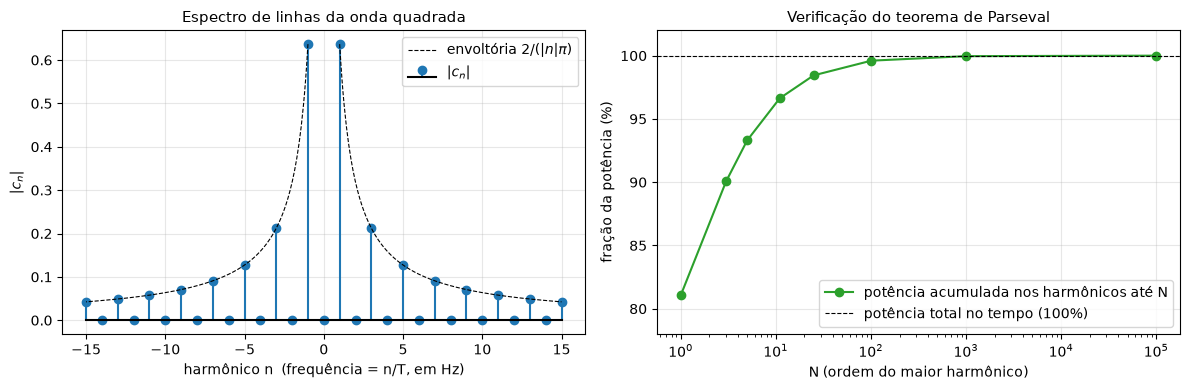

In [11]:
ordens = np.arange(-15, 16)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.stem(ordens, modulo_cn(ordens), linefmt=COR["original"], markerfmt="o", basefmt="k-",
         label="$|c_n|$")
n_cont = np.linspace(1, 15, 200)
ax1.plot(n_cont, 2 / (np.pi * n_cont), "k--", lw=0.8, label=r"envoltória $2/(|n|\pi)$")
ax1.plot(-n_cont, 2 / (np.pi * n_cont), "k--", lw=0.8)
ax1.set(xlabel="harmônico n  (frequência = n/T, em Hz)", ylabel="$|c_n|$",
        title="Espectro de linhas da onda quadrada")
ax1.legend()

ax2.semilogx(tabela_parseval["N"], tabela_parseval["fração da potência (%)"], "o-",
             color=COR["filtrado"], label="potência acumulada nos harmônicos até N")
ax2.axhline(100, color="k", ls="--", lw=0.8, label="potência total no tempo (100%)")
ax2.set(xlabel="N (ordem do maior harmônico)", ylabel="fração da potência (%)", ylim=(78, 102),
        title="Verificação do teorema de Parseval")
ax2.legend(loc="lower right")
salvar_fig(fig, "fig04_espectro_linhas_parseval.png")

No gráfico da esquerda, a onda quadrada só tem energia em frequências bem definidas, os múltiplos ímpares de $1/T$, e nada entre elas. As alturas acompanham a envoltória $2/(|n|\pi)$. O espectro é espelhado em relação a $n=0$ porque, para sinal real, $|c_{-n}|=|c_n|$. Por isso daqui em diante olho só para as frequências positivas, que é o que a `rfft` devolve.

No gráfico da direita, a soma $\sum|c_n|^2$ vai se aproximando de $1$, que é a potência calculada no tempo. Parseval confere. Achei interessante o quanto a fundamental pesa: sozinha ela carrega $8/\pi^2\approx 81\%$ da potência, e com harmônicos até $N=11$ já passa de $96\%$. Mas chegar perto de 100% é demorado (o que falta cai como $1/N$), de novo porque os coeficientes decaem devagar.

Isso combina com o que vi em Gibbs: o pico continua lá para todo $N$, mas a energia do erro vai sumindo. Em termos de energia, quase tudo do sinal mora nos primeiros harmônicos.

**Ponte para a Etapa 2.** Uma nota musical sustentada é, com boa aproximação, um sinal periódico: uma soma de senoides em $f_0, 2f_0, 3f_0,\dots$, do mesmo jeito que uma série de Fourier. A frequência $f_0$ diz qual é a nota, e o conjunto das amplitudes dos harmônicos (o equivalente dos $|c_n|$ acima) dá o **timbre**. Até aqui fui dos coeficientes para o sinal. Agora vou no sentido contrário: parto de uma gravação e uso a FFT para medir o espectro de linhas dela.

<a id="etapa2"></a>
# Etapa 2 — Do tempo para a frequência

## 2.1 O sinal: um Lá4 de violão

O arquivo `data/la4_violao.wav` é uma gravação real de um **Lá4 de violão, tocado na corda Sol** (14ª casa, dinâmica *mezzo-forte*), retirada do acervo *Musical Instrument Samples* dos Electronic Music Studios da Universidade de Iowa, que é de uso livre. O script `scripts/preparar_audio.py` recorta essa nota do arquivo original e a reamostra de 96 kHz para 48 kHz (detalhes no README).

Passos do carregamento:

1. ler o WAV e guardar a taxa de amostragem $f_s$;
2. converter para mono (média dos canais, se houver mais de um);
3. remover o conteúdo **subsônico** (abaixo de 20 Hz) com um passa-altas de fase zero. A gravação tem uma oscilação muito lenta que não é som da nota (é inaudível; provavelmente ruído de ambiente ou do microfone) mas carrega a maior parte da energia bruta do arquivo, e atrapalharia a normalização e os gráficos no tempo;
4. normalizar para pico igual a 1.

In [12]:
def carregar_audio(caminho):
    """Lê um WAV e devolve (fs, amostras em ponto flutuante). Interrompe se o arquivo não existir."""
    if not Path(caminho).exists():
        raise FileNotFoundError(f"Áudio não encontrado: {caminho}. Rode scripts/preparar_audio.py.")
    fs, dados = wavfile.read(caminho)
    if np.issubdtype(dados.dtype, np.integer):
        dados = dados / np.iinfo(dados.dtype).max
    return fs, dados.astype(float)


def para_mono(x):
    """Faz a média dos canais se o sinal for estéreo."""
    return x.mean(axis=1) if x.ndim == 2 else x


def remover_subsonico(x, fs, f_corte=20.0, ordem=4):
    """Passa-altas Butterworth de fase zero em 20 Hz: tira a deriva lenta, inaudível."""
    sos = signal.butter(ordem, f_corte, btype="highpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, x)


def normalizar(x, pico=1.0):
    """Escala o sinal para que o maior valor absoluto seja `pico`."""
    return pico * x / np.max(np.abs(x))


fs, bruto = carregar_audio(ARQ_AUDIO)
bruto = para_mono(bruto)
fracao_subsonica = 1 - np.mean(remover_subsonico(bruto, fs) ** 2) / np.mean(bruto ** 2)
x_limpo = normalizar(remover_subsonico(bruto, fs))
t_s = np.arange(len(x_limpo)) / fs

print(f"Taxa de amostragem fs = {fs} Hz   (limite de Nyquist fs/2 = {fs / 2:.0f} Hz)")
print(f"Número de amostras    = {len(x_limpo)}")
print(f"Duração               = {len(x_limpo) / fs:.3f} s")
print(f"Energia abaixo de 20 Hz removida no carregamento: {100 * fracao_subsonica:.1f}% da energia bruta")

Taxa de amostragem fs = 48000 Hz   (limite de Nyquist fs/2 = 24000 Hz)
Número de amostras    = 96000
Duração               = 2.000 s
Energia abaixo de 20 Hz removida no carregamento: 67.6% da energia bruta


In [13]:
# Trecho estável: 1 s logo depois do ataque (a palhetada), onde a nota já "assentou"
T_INICIO, DUR_TRECHO = 0.30, 1.00            # s
i0 = int(T_INICIO * fs)
trecho = x_limpo[i0:i0 + int(DUR_TRECHO * fs)]
t_trecho = t_s[i0:i0 + len(trecho)]
N_trecho = len(trecho)
print(f"Trecho analisado: de {T_INICIO:.2f} s a {T_INICIO + DUR_TRECHO:.2f} s "
      f"-> {N_trecho} amostras, resolução em frequência Δf = fs/N = {fs / N_trecho:.2f} Hz")

Trecho analisado: de 0.30 s a 1.30 s -> 48000 amostras, resolução em frequência Δf = fs/N = 1.00 Hz


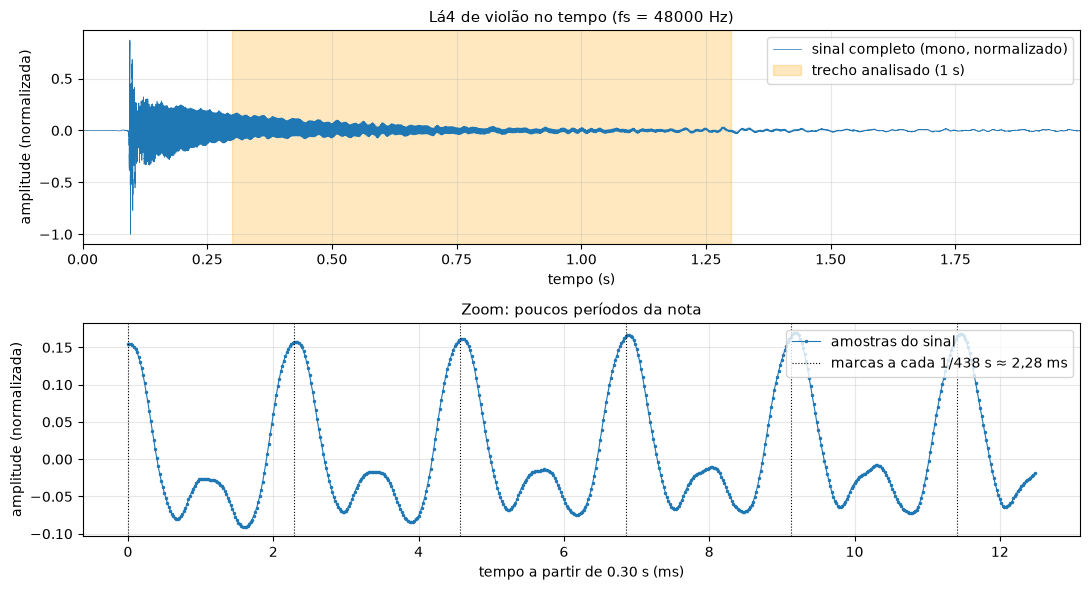

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6))
ax1.plot(t_s, x_limpo, color=COR["original"], lw=0.5, label="sinal completo (mono, normalizado)")
ax1.axvspan(T_INICIO, T_INICIO + DUR_TRECHO, color="orange", alpha=0.25, label="trecho analisado (1 s)")
ax1.set(xlabel="tempo (s)", ylabel="amplitude (normalizada)", xlim=(0, t_s[-1]),
        title=f"Lá4 de violão no tempo (fs = {fs} Hz)")
ax1.legend(loc="upper right")

zoom = slice(i0, i0 + int(0.0125 * fs))      # 12,5 ms ≈ 5 períodos e meio
ax2.plot(1e3 * (t_s[zoom] - T_INICIO), x_limpo[zoom], ".-", color=COR["original"], ms=3, lw=0.8,
         label="amostras do sinal")
for k in range(6):
    ax2.axvline(1e3 * k / 438.0, color="k", ls=":", lw=0.8,
                label="marcas a cada 1/438 s ≈ 2,28 ms" if k == 0 else None)
ax2.set(xlabel=f"tempo a partir de {T_INICIO:.2f} s (ms)", ylabel="amplitude (normalizada)",
        title="Zoom: poucos períodos da nota")
ax2.legend(loc="upper right")
salvar_fig(fig, "fig05_sinal_no_tempo.png")

No gráfico de cima aparece o formato que se espera de uma corda dedilhada: um ataque brusco (o dedo soltando a corda, em $t\approx 0{,}09$ s) e depois um decaimento, porque ninguém repõe a energia que a corda vai perdendo. Essa nota, aguda e tocada lá no alto do braço, morre rápido: em pouco mais de 1 s o som já se confunde com o ruído de fundo. Não existe um trecho realmente estável para analisar, então fiquei com 1 s logo depois do ataque (faixa laranja), onde o estalo inicial já passou e o sinal ainda está forte.

No zoom dá para ver que o sinal é **quase periódico**. O mesmo desenho se repete a cada $\approx 2{,}28$ ms (linhas pontilhadas), o que já aponta para uma fundamental perto de $1/0{,}00228\approx 438$ Hz. Duas coisas chamam a atenção. A primeira é que o desenho de cada período não é uma senoide limpa: há um pico alto e, no meio do período, um "calombo" menor. Isso é sinal de que existe pelo menos um harmônico forte somado à fundamental, como na Etapa 1. A segunda é que os períodos não são idênticos: a amplitude cai aos poucos e a linha de base sobe e desce lentamente, por causa de um ruído de baixa frequência que veio na gravação.

Tirar essas medidas no olho, pelo gráfico do tempo, é impreciso. É para isso que serve a transformada de Fourier.

## 2.2 FFT, janelamento e vazamento espectral

A Transformada Discreta de Fourier (calculada pela FFT) de $N$ amostras $x[k]$ tomadas a $f_s$ amostras por segundo é

$$X[m]=\sum_{k=0}^{N-1}x[k]\,e^{-i2\pi mk/N},\qquad f_m=m\,\frac{f_s}{N},\quad m=0,\dots,N/2 .$$

O eixo de frequência vem **inteiramente de $f_s$**: o espaçamento entre raias é $\Delta f=f_s/N$ (aqui 1 Hz, pois o trecho tem 1 s) e a maior frequência representável é $f_s/2$. Uso `rfft`/`rfftfreq`, que devolvem só as frequências positivas (o sinal é real, então a metade negativa é o conjugado da positiva, como visto com $c_{-n}=\overline{c_n}$).

**Vazamento espectral.** A FFT trata o trecho como se fosse um período de um sinal periódico. Se o trecho não contém um número inteiro de períodos da nota, as pontas não "emendam" e surge uma descontinuidade artificial, que (como na onda quadrada) espalha energia por todas as frequências. Multiplicar o trecho por uma **janela de Hann**, $w[k]=\tfrac12\left(1-\cos\frac{2\pi k}{N}\right)$, leva as pontas suavemente a zero e reduz muito esse espalhamento, ao custo de alargar um pouco cada pico.

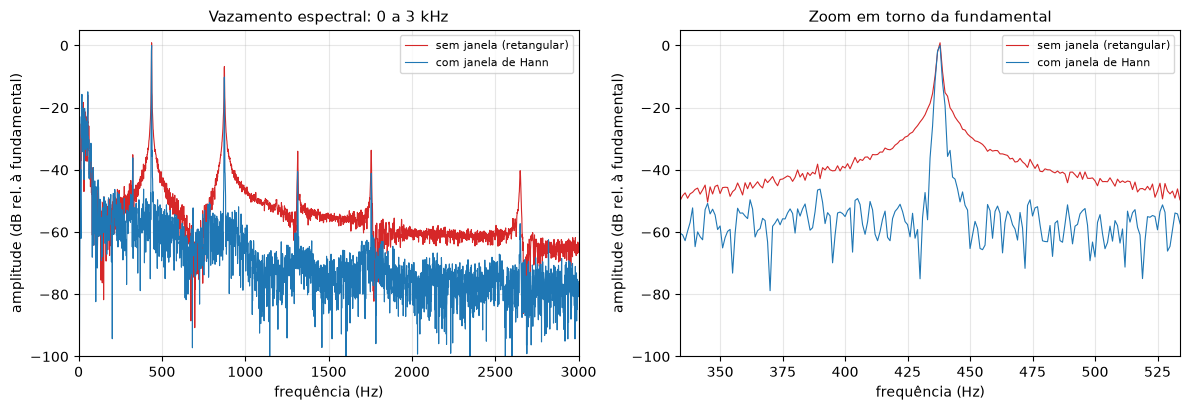

In [15]:
def espectro(x, fs, janela="hann"):
    """Espectro de amplitude unilateral via rFFT.

    A divisão por sum(w)/2 compensa o ganho da janela: uma senoide de amplitude A
    aparece com pico ≈ A, qualquer que seja a janela. Retorna (f em Hz, amplitude).
    """
    w = signal.get_window(janela, len(x))
    X = fft.rfft(x * w)
    f = fft.rfftfreq(len(x), d=1 / fs)        # eixo em Hz, calculado a partir de fs
    return f, 2 * np.abs(X) / w.sum()


f_tr, amp_ret = espectro(trecho, fs, janela="boxcar")   # janela retangular = sem janela
_, amp_hann = espectro(trecho, fs, janela="hann")
ref_db = amp_hann[f_tr > 70].max()                      # referência: maior pico musical (0 dB)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (fa, fb) in zip((ax1, ax2), [(0, 3000), (334, 534)]):
    ax.plot(f_tr, em_db(amp_ret, ref_db), color=COR["ruidoso"], lw=0.8, label="sem janela (retangular)")
    ax.plot(f_tr, em_db(amp_hann, ref_db), color=COR["original"], lw=0.8, label="com janela de Hann")
    ax.set(xlim=(fa, fb), ylim=(-100, 5), xlabel="frequência (Hz)",
           ylabel="amplitude (dB rel. à fundamental)")
    ax.legend(loc="upper right", fontsize=8)
ax1.set_title("Vazamento espectral: 0 a 3 kHz")
ax2.set_title("Zoom em torno da fundamental")
salvar_fig(fig, "fig06_vazamento_janela.png")

As duas curvas são o espectro do *mesmo* trecho de áudio. A única diferença é a janela.

Sem janela (vermelho), cada pico vem com umas "saias" largas que caem devagar. Essas saias não existem no som: são o vazamento, causado por termos cortado o trecho de forma abrupta. O problema é que elas formam um chão falso, e tudo o que estiver abaixo dele entre os harmônicos fica escondido.

Com a janela de Hann (azul), as saias caem muito mais rápido e o fundo entre os harmônicos desce dezenas de dB. Aí sim aparece o verdadeiro piso de ruído da gravação. O preço está no zoom: o pico fica um pouco mais gordo (o lóbulo principal da Hann tem o dobro da largura do retangular), então perde-se um pouco de resolução em frequência. Achei uma troca que vale a pena.

O curioso é que isso é a Etapa 1 de novo. Cortar um trecho no tempo é multiplicar o sinal por um retângulo, que tem bordas com salto, e função com salto tem espectro que decai devagar (o $1/n$ da onda quadrada). A janela de Hann vai a zero suavemente nas pontas, e por isso o espectro dela decai rápido. Daqui para a frente uso sempre a Hann nas análises.

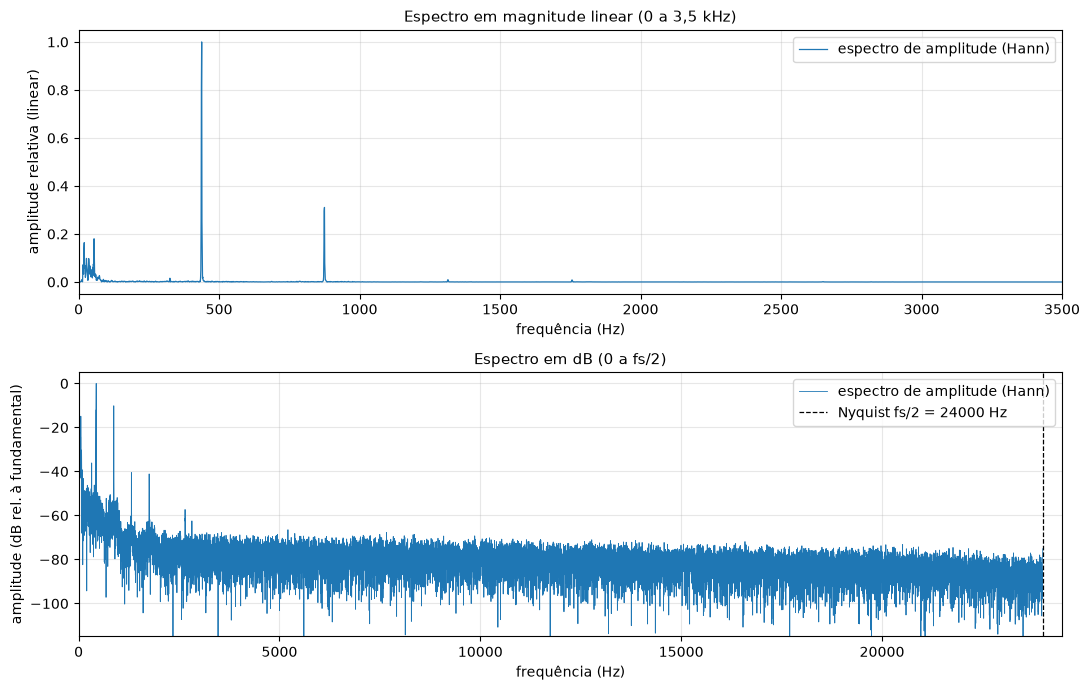

In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))
ax1.plot(f_tr, amp_hann / ref_db, color=COR["original"], lw=0.9, label="espectro de amplitude (Hann)")
ax1.set(xlim=(0, 3500), xlabel="frequência (Hz)", ylabel="amplitude relativa (linear)",
        title="Espectro em magnitude linear (0 a 3,5 kHz)")
ax1.legend(loc="upper right")

ax2.plot(f_tr, em_db(amp_hann, ref_db), color=COR["original"], lw=0.6, label="espectro de amplitude (Hann)")
ax2.axvline(fs / 2, color="k", ls="--", lw=0.9, label=f"Nyquist fs/2 = {fs / 2:.0f} Hz")
ax2.set(xlim=(0, fs / 2 * 1.02), ylim=(-115, 5), xlabel="frequência (Hz)",
        ylabel="amplitude (dB rel. à fundamental)",
        title="Espectro em dB (0 a fs/2)")
ax2.legend(loc="upper right")
salvar_fig(fig, "fig07_espectro_linear_db.png")

São duas vistas do mesmo espectro, e cada uma serve para responder uma pergunta.

A escala linear (em cima) mostra o que manda no som. É um **espectro de linhas**, parecido com o da onda quadrada: picos finos e igualmente espaçados. Tem um pico muito maior que os outros perto de 438 Hz, a fundamental, e um segundo, com mais ou menos um terço da altura, perto de 875 Hz. Do terceiro harmônico em diante não se enxerga nada nessa escala. Bem à esquerda, abaixo de 70 Hz, há um amontoado baixo que não faz parte da série: é ruído grave que veio na gravação.

A escala em dB (embaixo) comprime tudo e mostra o que a linear esconde. Aparecem mais alguns harmônicos fracos, até uns 2,7 kHz, e o **piso de ruído**, que vai de cerca de $-55$ dB perto da fundamental até uns $-80$ dB nas frequências altas.

Acima de $\sim$3 kHz não tem mais pico nenhum, só piso. A parte sustentada da nota não tem nada relevante ali, e vou usar essa informação na Etapa 3 para escolher onde cortar com o passa-baixas.

## 2.3 Fundamental e harmônicos

Para medir as frequências usei `scipy.signal.find_peaks` no espectro em dB. Critérios, e por que cada um:

- **Altura mínima: 15 dB acima do piso local.** O piso é estimado por uma mediana móvel do espectro em dB (janela de $\pm$100 Hz). Um pico só conta se sobressai claramente do ruído à sua volta; como o piso muda ao longo do espectro, um limiar fixo não serviria.
- **Frequência mínima de 70 Hz:** a nota mais grave de um violão é o Mi2 (82 Hz); abaixo disso não pode haver fundamental de corda, só ruído.
- **Fundamental = pico mais forte.** Vale para esta gravação (o gráfico linear acima não deixa dúvida), mas não é regra geral: há instrumentos em que o 2º harmônico é mais forte que a fundamental.
- **Harmônico $k$ = pico mais forte a menos de 1,5% de $k f_0$.** Picos que não estão perto de um múltiplo inteiro de $f_0$ são descartados.

Como a grade da FFT tem passo de 1 Hz, refinei cada pico por **interpolação parabólica** dos três pontos em torno do máximo, o que dá resolução melhor que $\Delta f$.

In [17]:
def refinar_pico(f, a_db, i):
    """Interpolação parabólica em dB em torno do índice i. Retorna (frequência, nível) refinados."""
    y0, y1, y2 = a_db[i - 1], a_db[i], a_db[i + 1]
    desloc = 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)       # deslocamento em frações de raia
    return f[i] + desloc * (f[1] - f[0]), y1 - 0.25 * (y0 - y2) * desloc


def piso_local(a_db, largura=201):
    """Piso de ruído local: mediana móvel do espectro em dB (janela de `largura` raias)."""
    return signal.medfilt(a_db, kernel_size=largura)


def detectar_harmonicos(f, amp, f_min=70.0, margem_db=15.0, tolerancia=0.015):
    """Acha f0 (pico mais forte acima de f_min) e, para cada k, o pico mais forte perto de k·f0."""
    a_db = em_db(amp)
    indices, _ = signal.find_peaks(a_db, height=piso_local(a_db) + margem_db)
    indices = indices[f[indices] >= f_min]
    picos = np.array([refinar_pico(f, a_db, i) for i in indices])      # colunas: freq, dB
    f0, db0 = picos[np.argmax(picos[:, 1])]
    linhas = []
    for k in range(1, int(f[-1] // f0) + 1):
        perto = picos[np.abs(picos[:, 0] - k * f0) <= tolerancia * k * f0]
        if len(perto) == 0:
            continue
        freq, nivel = perto[np.argmax(perto[:, 1])]
        linhas.append({"harmônico k": k, "frequência (Hz)": freq,
                       "amplitude relativa": 10 ** ((nivel - db0) / 20),
                       "amplitude (dB)": nivel - db0, "razão f/f0": freq / f0})
    return f0, pd.DataFrame(linhas)


f0, tabela_harm = detectar_harmonicos(f_tr, amp_hann)
erro_hz = f0 - F_NOTA
erro_cents = 1200 * np.log2(f0 / F_NOTA)
print(f"f0 medida       = {f0:.2f} Hz")
print(f"f0 teórica (Lá4) = {F_NOTA:.2f} Hz")
print(f"erro            = {erro_hz:+.2f} Hz  ({100 * erro_hz / F_NOTA:+.2f}%)  = {erro_cents:+.1f} cents")
display(tabela_harm.style.format({"frequência (Hz)": "{:.2f}", "amplitude relativa": "{:.4f}",
                                  "amplitude (dB)": "{:.1f}", "razão f/f0": "{:.4f}"}).hide(axis="index"))

f0 medida       = 437.63 Hz
f0 teórica (Lá4) = 440.00 Hz
erro            = -2.37 Hz  (-0.54%)  = -9.4 cents


harmônico k,frequência (Hz),amplitude relativa,amplitude (dB),razão f/f0
1,437.63,1.0000,0.0,1.0000
2,874.53,0.3251,-9.8,1.9983
3,1314.46,0.0090,-40.9,3.0036
4,1756.19,0.0080,-42.0,4.0130
6,2649.67,0.0013,-57.9,6.0546


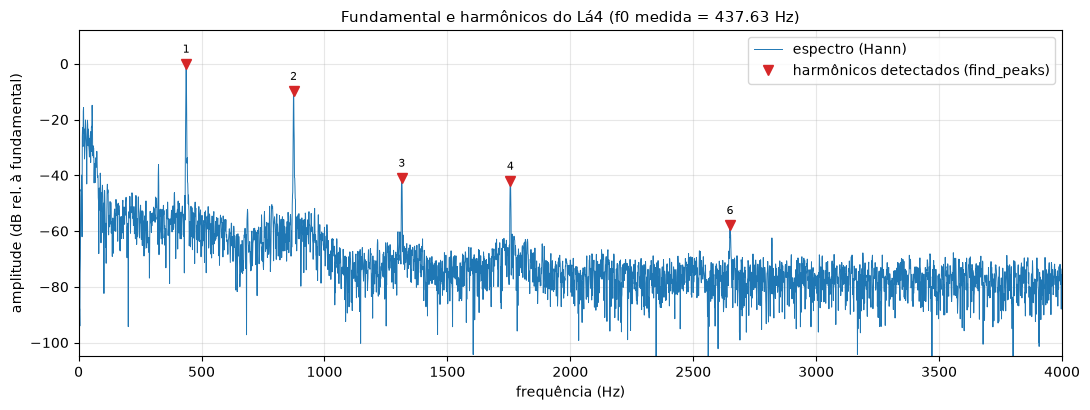

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(f_tr, em_db(amp_hann, ref_db), color=COR["original"], lw=0.7, label="espectro (Hann)")
ax.plot(tabela_harm["frequência (Hz)"], tabela_harm["amplitude (dB)"], "v", color=COR["ruidoso"],
        ms=7, label="harmônicos detectados (find_peaks)")
for _, linha in tabela_harm.iterrows():
    ax.annotate(f"{int(linha['harmônico k'])}", (linha["frequência (Hz)"], linha["amplitude (dB)"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set(xlim=(0, 4000), ylim=(-105, 12), xlabel="frequência (Hz)",
       ylabel="amplitude (dB rel. à fundamental)",
       title=f"Fundamental e harmônicos do Lá4 (f0 medida = {f0:.2f} Hz)")
ax.legend(loc="upper right")
salvar_fig(fig, "fig08_harmonicos.png")

**A fundamental.** Medi $f_0\approx 437{,}6$ Hz, contra os 440 Hz teóricos do Lá4. O erro é de $-2{,}4$ Hz ($-0{,}54\%$), ou cerca de **$-9$ cents** (um cent é 1/100 de semitom; uma diferença de 5 a 10 cents está no limite do que um ouvido treinado percebe).

A primeira coisa que fiz foi desconfiar da minha medida, mas ela não explica a diferença. A resolução da FFT aqui é de 1 Hz e, com a interpolação parabólica, a incerteza fica em décimos de hertz, bem menor que os 2,4 Hz. A explicação mais simples é que a nota gravada está mesmo um pouquinho baixa. Em um violão de verdade isso é normal: a afinação nunca é exata e, em nota pisada no alto do braço (aqui é a 14ª casa), a posição do traste e a força do dedo mexem alguns cents. No fim, o espectro mede o som que foi gravado, e não o nome da nota.

**Os harmônicos.** Encontrei os harmônicos 1, 2, 3, 4 e 6, todos praticamente em múltiplos inteiros de $f_0$ (coluna "razão $f/f_0$"). Isso confirma que a nota pode ser tratada como uma série de Fourier. Olhando com mais cuidado, do 3º em diante a razão fica *um pouco acima* do inteiro, e cada vez mais (3,004; 4,013; 6,055). Isso tem nome: **inarmonicidade**. Uma corda real tem rigidez, e a rigidez faz os modos altos vibrarem um pouco mais rápido que os múltiplos exatos. O efeito cresce quando o trecho que vibra é curto e grosso, que é o caso da corda Sol pisada na 14ª casa.

**As amplitudes.** A fundamental domina. O 2º harmônico tem cerca de um terço da amplitude dela ($-10$ dB) e os outros ficam abaixo de 1% ($-40$ dB ou menos). O 5º harmônico não apareceu: se existe, está a menos de 15 dB do piso. Uma explicação possível é a corda ter sido tocada perto de um nó desse modo, que nesse caso quase não é excitado. Não tenho como confirmar isso só com o áudio, então fica como hipótese.

**Picos que não são harmônicos.** O espectro tem alguns picos finos que o meu critério descartou, corretamente, por não estarem perto de múltiplos de $f_0$. Dois exemplos estão em torno de 325 Hz e de 2,8 kHz. O de 325 Hz fica perto do Mi4 da corda Mi solta (329,6 Hz no padrão), o que me faz pensar em outra corda do violão vibrando por simpatia. Também é só uma hipótese.

## 2.4 Taxa de amostragem, limite de Nyquist e aliasing

Amostrar é medir o sinal a cada $1/f_s$ segundos. O **teorema da amostragem** (Nyquist–Shannon) garante que um sinal pode ser reconstruído exatamente a partir das amostras se não tiver conteúdo acima de $f_s/2$, a **frequência de Nyquist**. Aqui $f_s=48$ kHz, logo $f_s/2=24$ kHz, acima do limite da audição humana ($\sim$20 kHz) e muito acima do último harmônico relevante da nota ($\sim$2,7 kHz).

Se houver conteúdo acima de $f_s/2$, ele não desaparece: é **rebatido** para dentro da faixa $[0, f_s/2]$ e aparece em uma frequência falsa, $f_{alias}=|f-k f_s|$ (para o inteiro $k$ que traz o resultado para a faixa). Isso é o *aliasing*. Duas demonstrações: primeiro com uma senoide de teste, depois com o próprio violão.

Senoide de 7000 Hz amostrada a 10000 Hz (Nyquist = 5000 Hz)
Frequência prevista do alias: 3000 Hz | pico medido no espectro: 3000 Hz


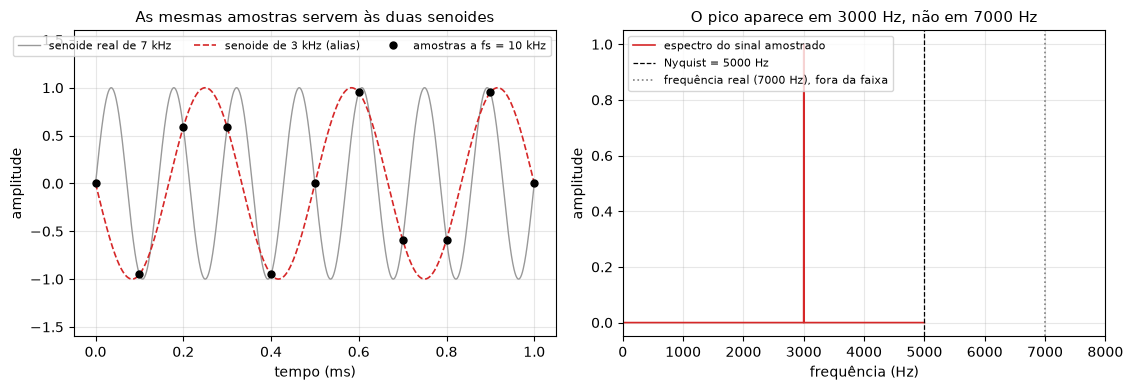

In [19]:
def frequencia_alias(f, fs_amostragem):
    """Frequência aparente (em [0, fs/2]) de uma componente em f amostrada a fs."""
    resto = np.mod(f, fs_amostragem)
    return np.minimum(resto, fs_amostragem - resto)


F_TESTE, FS_BAIXA = 7000.0, 10000.0                 # senoide de 7 kHz amostrada a 10 kHz
f_ap = frequencia_alias(F_TESTE, FS_BAIXA)
t_cont = np.arange(0, 1e-3, 1e-6)                   # grade fina, faz o papel do sinal "contínuo"
t_amos = np.arange(0, 1e-3 + 1e-9, 1 / FS_BAIXA)
seno_teste = np.sin(2 * np.pi * F_TESTE * np.arange(int(FS_BAIXA)) / FS_BAIXA)   # 1 s amostrado
f_al, amp_al = espectro(seno_teste, FS_BAIXA)
print(f"Senoide de {F_TESTE:.0f} Hz amostrada a {FS_BAIXA:.0f} Hz (Nyquist = {FS_BAIXA / 2:.0f} Hz)")
print(f"Frequência prevista do alias: {f_ap:.0f} Hz | pico medido no espectro: {f_al[np.argmax(amp_al)]:.0f} Hz")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(1e3 * t_cont, np.sin(2 * np.pi * F_TESTE * t_cont), color="0.6", lw=1,
         label=f"senoide real de {F_TESTE / 1e3:.0f} kHz")
ax1.plot(1e3 * t_cont, -np.sin(2 * np.pi * f_ap * t_cont), color=COR["ruidoso"], lw=1.2, ls="--",
         label=f"senoide de {f_ap / 1e3:.0f} kHz (alias)")
ax1.plot(1e3 * t_amos, np.sin(2 * np.pi * F_TESTE * t_amos), "ko", ms=5,
         label=f"amostras a fs = {FS_BAIXA / 1e3:.0f} kHz")
ax1.set(xlabel="tempo (ms)", ylabel="amplitude", ylim=(-1.6, 1.6),
        title="As mesmas amostras servem às duas senoides")
ax1.legend(loc="upper right", fontsize=8, ncol=3)

ax2.plot(f_al, amp_al, color=COR["ruidoso"], lw=1.2, label="espectro do sinal amostrado")
ax2.axvline(FS_BAIXA / 2, color="k", ls="--", lw=0.9, label=f"Nyquist = {FS_BAIXA / 2:.0f} Hz")
ax2.axvline(F_TESTE, color="0.5", ls=":", lw=1.2, label=f"frequência real ({F_TESTE:.0f} Hz), fora da faixa")
ax2.set(xlim=(0, 8000), xlabel="frequência (Hz)", ylabel="amplitude",
        title=f"O pico aparece em {f_ap:.0f} Hz, não em {F_TESTE:.0f} Hz")
ax2.legend(loc="upper left", fontsize=8)
salvar_fig(fig, "fig09_aliasing_senoide.png")

A senoide de 7 kHz (em cinza) foi amostrada a 10 kHz, ou seja, ela está acima do limite de Nyquist, que nesse caso é 5 kHz. À esquerda, os pontos pretos são as amostras. O que impressiona é que por esses mesmos pontos passa, perfeitamente, uma senoide de 3 kHz (tracejada). Depois de amostrado, o sinal não guarda mais nenhuma pista de qual das duas era a verdadeira, e a FFT (à direita) mostra o pico em $|7000-10000|=3000$ Hz.

Os 7 kHz se disfarçaram de 3 kHz, e vem daí o nome *alias*. É como se o espectro fosse uma folha de papel dobrada em $f_s/2$: o que estava acima da dobra cai em cima do que estava abaixo.

harmônico k,frequência real (Hz),aparece em (Hz)
2,874.5,625.5
3,1314.5,185.5
4,1756.2,256.2
6,2649.7,350.3


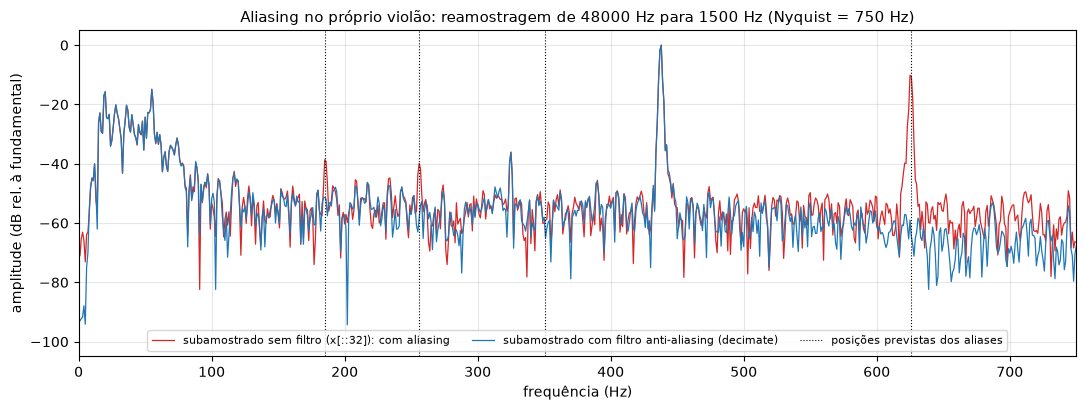

In [20]:
FATOR = 32                                           # 48 kHz -> 1,5 kHz (Nyquist = 750 Hz)
fs_sub = fs / FATOR
sub_ingenuo = trecho[::FATOR]                        # só descarta amostras: provoca aliasing
sub_correto = signal.decimate(trecho, FATOR, ftype="fir", zero_phase=True)   # filtra antes de descartar

f_sub, amp_ing = espectro(sub_ingenuo, fs_sub)
_, amp_cor = espectro(sub_correto, fs_sub)

acima = tabela_harm[tabela_harm["frequência (Hz)"] > fs_sub / 2]
previsao_alias = pd.DataFrame({
    "harmônico k": acima["harmônico k"],
    "frequência real (Hz)": acima["frequência (Hz)"],
    "aparece em (Hz)": frequencia_alias(acima["frequência (Hz)"], fs_sub),
})
display(previsao_alias.style.format({"frequência real (Hz)": "{:.1f}", "aparece em (Hz)": "{:.1f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(f_sub, em_db(amp_ing, ref_db), color=COR["ruidoso"], lw=0.9,
        label=f"subamostrado sem filtro (x[::{FATOR}]): com aliasing")
ax.plot(f_sub, em_db(amp_cor, ref_db), color=COR["original"], lw=0.9,
        label="subamostrado com filtro anti-aliasing (decimate)")
for i, f_falsa in enumerate(previsao_alias["aparece em (Hz)"]):
    ax.axvline(f_falsa, color="k", ls=":", lw=0.8,
               label="posições previstas dos aliases" if i == 0 else None)
ax.set(xlim=(0, fs_sub / 2), ylim=(-105, 5), xlabel="frequência (Hz)",
       ylabel="amplitude (dB rel. à fundamental)",
       title=f"Aliasing no próprio violão: reamostragem de {fs} Hz para {fs_sub:.0f} Hz (Nyquist = {fs_sub / 2:.0f} Hz)")
ax.legend(loc="lower center", fontsize=8, ncol=3)
salvar_fig(fig, "fig10_aliasing_violao.png")

Aqui repeti o experimento com o próprio violão, baixando a taxa de amostragem de 48 kHz para 1,5 kHz de dois jeitos. Com 1,5 kHz o limite de Nyquist é 750 Hz. A fundamental (438 Hz) cabe, mas todos os outros harmônicos ficam acima do limite.

No jeito ingênuo (vermelho), que é só ficar com uma amostra a cada 32, os harmônicos acima de 750 Hz reaparecem em frequências falsas dentro da faixa. Eles caem exatamente onde a conta $f_{alias}=|f-kf_s|$ previa (linhas pontilhadas e tabela). O caso que mais salta aos olhos é o 2º harmônico: o pico real de $\approx$875 Hz aparece em $1500-875\approx 625$ Hz, quase com a mesma altura. E 625 Hz **não é múltiplo de $f_0$**, então isso soaria como uma segunda nota, estranha ao Lá. O piso de ruído também sobe, porque todo o ruído que estava entre 750 Hz e 24 kHz é dobrado para dentro da faixa.

No jeito correto (azul), passei um filtro passa-baixas *antes* de jogar amostras fora. Ele tira o que está acima de 750 Hz e os picos falsos desaparecem. Sobra só a fundamental, que é tudo o que essa taxa de amostragem consegue representar direito.

A lição prática é que o aliasing não tem conserto depois que o sinal foi amostrado, porque o alias fica igualzinho a um conteúdo legítimo. É por isso que todo conversor A/D tem um passa-baixas analógico antes do amostrador, e que se escolhe $f_s$ com folga em relação à maior frequência que interessa.

## 2.5 Onde está a energia?

Usando Parseval (agora na versão discreta), a energia do trecho pode ser repartida por faixas de frequência somando $|X[m]|^2$ nas raias de cada faixa.

In [21]:
def potencia_na_faixa(x, fs, f_min, f_max):
    """Potência média de x contida em [f_min, f_max), somando |X|² (Parseval discreto)."""
    X = fft.rfft(x)
    f = fft.rfftfreq(len(x), d=1 / fs)
    densidade = 2 * np.abs(X) ** 2 / len(x) ** 2
    densidade[0] /= 2                                  # a raia de 0 Hz não tem par negativo
    return densidade[(f >= f_min) & (f < f_max)].sum()


def reparticao_de_energia(x, fs, tabela, meia_largura=15.0):
    """Fração da energia em cada harmônico (±meia_largura Hz) e nas regiões fora deles."""
    total = np.mean(x ** 2)
    linhas, soma_harm = [], 0.0
    for _, h in tabela.iterrows():
        p = potencia_na_faixa(x, fs, h["frequência (Hz)"] - meia_largura, h["frequência (Hz)"] + meia_largura)
        soma_harm += p
        linhas.append({"faixa": f"harmônico {int(h['harmônico k'])} ({h['frequência (Hz)']:.0f} Hz)",
                       "energia (%)": 100 * p / total})
    graves = potencia_na_faixa(x, fs, 0, 70)
    linhas.append({"faixa": "abaixo de 70 Hz (ruído grave da gravação)", "energia (%)": 100 * graves / total})
    linhas.append({"faixa": "todo o resto (entre harmônicos e acima deles)",
                   "energia (%)": 100 * (total - soma_harm - graves) / total})
    return pd.DataFrame(linhas)


tabela_energia = reparticao_de_energia(trecho, fs, tabela_harm)
piso_medio = np.median(em_db(amp_hann, ref_db)[(f_tr > 6000) & (f_tr < 20000)])
print(f"Piso de ruído mediano entre 6 e 20 kHz: {piso_medio:.1f} dB em relação à fundamental (por raia de 1 Hz)")
display(tabela_energia.style.format({"energia (%)": "{:.4f}"}).hide(axis="index"))

Piso de ruído mediano entre 6 e 20 kHz: -80.9 dB em relação à fundamental (por raia de 1 Hz)


faixa,energia (%)
harmônico 1 (438 Hz),72.8000
harmônico 2 (875 Hz),19.9255
harmônico 3 (1314 Hz),0.0468
harmônico 4 (1756 Hz),0.0487
harmônico 6 (2650 Hz),0.0221
abaixo de 70 Hz (ruído grave da gravação),5.4517
todo o resto (entre harmônicos e acima deles),1.7051


**Juntando tudo o que a Etapa 2 mostrou**

*Quais frequências dominam.* A fundamental em $\approx$438 Hz fica com cerca de 73% da energia do trecho e o 2º harmônico com outros 20%. Todos os demais harmônicos juntos não chegam a 0,2%. É parecido com o que Parseval mostrou na onda quadrada, só que mais extremo: dois termos da série carregam mais de 90% da energia.

*O timbre.* A altura que se ouve, um Lá levemente baixo, vem de $f_0$. O que faz esse Lá soar como violão, e não como flauta ou piano, é a receita de amplitudes dos harmônicos (a tabela da seção 2.3) e o jeito como ela muda no tempo: ataque rápido e brilhante, depois um decaimento em que os agudos morrem antes dos graves. Na parte sustentada esta nota tem um som "doce", pouco brilhante, quase uma senoide com a sua oitava. Isso é esperado de corda de nylon tocada no alto do braço. Uma onda quadrada com a mesma $f_0$, com harmônicos caindo só como $1/n$, soaria bem mais áspera.

*O piso de ruído.* Entre os harmônicos e acima de 3 kHz o espectro não vai a zero. Fica em um patamar em torno de $-80$ dB em relação à fundamental (por raia de 1 Hz). É o ruído de fundo da gravação (microfone, pré-amplificador, sala), mais o que restou do estalo do ataque. Existe também uma região de ruído **grave**, abaixo de $\sim$70 Hz, bem mais forte que o piso das altas. Ela não tem relação harmônica com a nota e responde por uns 5% da energia do trecho. Eu não esperava tanto: mesmo uma gravação de estúdio não é perfeitamente limpa.

*Tempo e frequência.* Tudo o que eu via no gráfico do tempo tem um correspondente no espectro. A repetição a cada 2,28 ms é o pico em 438 Hz. O "calombo" no meio de cada período é o 2º harmônico. A ondulação lenta da linha de base é o ruído grave. E o fato de a nota decair é o motivo de os picos terem uma pequena largura, em vez de serem linhas perfeitas. No tempo tudo isso aparece somado em uma curva só; na frequência cada coisa fica no seu lugar. É essa separação que vai permitir filtrar.

<a id="etapa3"></a>
# Etapa 3 — Filtrar e reconstruir

## 3.1 Contaminação controlada (sintética)

A gravação de estúdio é limpa: quase não há o que remover. Para estudar filtragem, **contaminei o sinal de propósito**, com interferências sintéticas cujos parâmetros eu conheço. Isso tem uma vantagem decisiva sobre usar uma gravação ruidosa "de verdade": como guardei o original limpo, posso **medir** quanto o filtro recuperou (SNR e erro RMS), em vez de apenas olhar os gráficos.

Somei ao sinal completo (2 s) duas interferências típicas de gravações reais:

1. **Zumbido da rede elétrica:** senoide em 60 Hz mais dois harmônicos fracos, em 120 Hz (amplitude 20% da de 60 Hz) e 180 Hz (10%). É o *hum* de aterramento ruim ou de cabos perto de transformadores. O conjunto é escalado para ter **SNR de 3 dB** em relação ao sinal, ou seja, o zumbido tem metade da potência da música: bem audível.
2. **Ruído branco gaussiano** com **SNR de 20 dB**: o chiado de fundo de um pré-amplificador ruim. "Branco" significa potência igual em todas as frequências, de 0 a $f_s/2$.

A relação sinal-ruído é definida por

$$\mathrm{SNR_{dB}}=10\log_{10}\frac{P_{sinal}}{P_{ruído}},\qquad P=\frac{1}{N}\sum_k x[k]^2 .$$

A semente do gerador é fixa (`default_rng(42)`), então o ruído é idêntico a cada execução.

In [22]:
SNR_ZUMBIDO_DB = 3.0                 # zumbido com metade da potência do sinal
SNR_BRANCO_DB = 20.0                 # ruído branco com 1% da potência do sinal
F_REDE = 60.0                        # Hz, frequência da rede elétrica no Brasil
AMPLITUDES_ZUMBIDO = (1.0, 0.2, 0.1) # amplitudes relativas em 60, 120 e 180 Hz


def potencia(x):
    """Potência média do sinal."""
    return np.mean(x ** 2)


def snr_db(referencia, sinal):
    """SNR de `sinal` tomando como ruído tudo o que difere da `referencia` limpa."""
    return 10 * np.log10(potencia(referencia) / potencia(sinal - referencia))


def escalar_para_snr(ruido, sinal, snr_alvo_db):
    """Escala `ruido` para que a razão P_sinal/P_ruido seja exatamente a SNR pedida."""
    return ruido * np.sqrt(potencia(sinal) / (potencia(ruido) * 10 ** (snr_alvo_db / 10)))


def gerar_zumbido(n_amostras, fs, rng):
    """Zumbido de rede: senoides em 60, 120 e 180 Hz com fases sorteadas."""
    tempo = np.arange(n_amostras) / fs
    fases = rng.uniform(0, 2 * np.pi, len(AMPLITUDES_ZUMBIDO))
    return sum(a * np.sin(2 * np.pi * (k + 1) * F_REDE * tempo + fase)
               for k, (a, fase) in enumerate(zip(AMPLITUDES_ZUMBIDO, fases)))


def contaminar(x, fs, rng):
    """Soma zumbido e ruído branco ao sinal. Retorna (sinal contaminado, zumbido, ruído branco)."""
    zumbido = escalar_para_snr(gerar_zumbido(len(x), fs, rng), x, SNR_ZUMBIDO_DB)
    branco = escalar_para_snr(rng.standard_normal(len(x)), x, SNR_BRANCO_DB)
    return x + zumbido + branco, zumbido, branco


x_ruidoso, zumbido, branco = contaminar(x_limpo, fs, rng)
print(f"SNR só do zumbido      : {10 * np.log10(potencia(x_limpo) / potencia(zumbido)):6.2f} dB")
print(f"SNR só do ruído branco : {10 * np.log10(potencia(x_limpo) / potencia(branco)):6.2f} dB")
print(f"SNR do sinal contaminado: {snr_db(x_limpo, x_ruidoso):6.2f} dB")
print(f"Amplitude do zumbido em 60 Hz: {np.sqrt(2 * potencia(zumbido) / sum(a * a for a in AMPLITUDES_ZUMBIDO)):.3f} "
      f"(o sinal limpo tem pico 1 e valor RMS {np.sqrt(potencia(x_limpo)):.3f})")

SNR só do zumbido      :   3.00 dB
SNR só do ruído branco :  20.00 dB
SNR do sinal contaminado:   2.91 dB
Amplitude do zumbido em 60 Hz: 0.053 (o sinal limpo tem pico 1 e valor RMS 0.054)


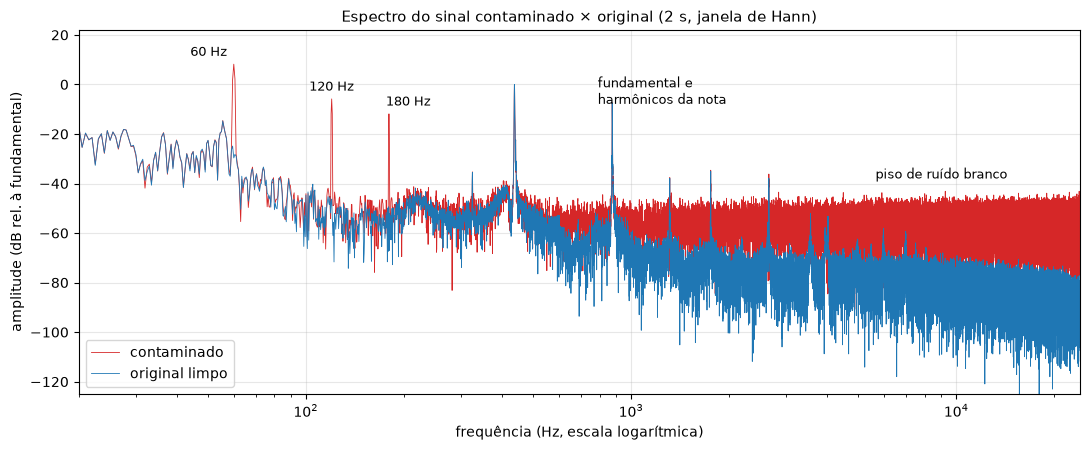

In [23]:
f_c, amp_limpo = espectro(x_limpo, fs)           # 2 s de sinal -> resolução de 0,5 Hz
_, amp_ruidoso = espectro(x_ruidoso, fs)
ref5 = amp_limpo[f_c > 70].max()                 # fundamental do sinal limpo = 0 dB

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.semilogx(f_c[1:], em_db(amp_ruidoso[1:], ref5), color=COR["ruidoso"], lw=0.6, label="contaminado")
ax.semilogx(f_c[1:], em_db(amp_limpo[1:], ref5), color=COR["original"], lw=0.6, label="original limpo")
for k, deslocamento in zip((1, 2, 3), (-18, 0, 14)):
    ax.annotate(f"{k * F_REDE:.0f} Hz", (k * F_REDE, em_db(amp_ruidoso[np.argmin(np.abs(f_c - k * F_REDE))], ref5)),
                textcoords="offset points", xytext=(deslocamento, 6), ha="center", fontsize=9)
ax.annotate("fundamental e\nharmônicos da nota", (f0, 0), textcoords="offset points",
            xytext=(60, -14), fontsize=9)
ax.annotate("piso de ruído branco", (9000, -38), ha="center", fontsize=9)
ax.set(xlim=(20, fs / 2), ylim=(-125, 22), xlabel="frequência (Hz, escala logarítmica)",
       ylabel="amplitude (dB rel. à fundamental)",
       title="Espectro do sinal contaminado × original (2 s, janela de Hann)")
ax.legend(loc="lower left")
salvar_fig(fig, "fig11_espectro_contaminado.png")

Comparando as duas curvas dá para decidir o que atacar, porque os dois tipos de sujeira aparecem de jeitos bem diferentes.

O zumbido é de **banda estreita**. São três linhas finíssimas, em 60, 120 e 180 Hz. A de 60 Hz é o componente mais forte do espectro inteiro, mais alta até que a fundamental da nota, e toda a potência dela cabe em uma fração de hertz.

O ruído branco é de **banda larga**. Ele levanta o piso do espectro por igual, em todas as frequências. Em cada raia ele é fraco, mas ocupa os 24 kHz inteiros, e é somando tudo isso que chega a 1% da potência do sinal.

O que me interessa continua onde estava: fundamental em $\approx$438 Hz e harmônicos até $\sim$2,7 kHz, **todos longe de 60 Hz**. A componente da nota mais próxima do zumbido é a própria fundamental, quase 380 Hz acima (perto de três oitavas). A fundamental e o 2º harmônico continuam dezenas de dB acima do novo piso. Já os harmônicos fracos (3º, 4º e 6º) agora sobressaem dele por apenas uns 10 dB.

Então cada sujeira pede uma ferramenta. Para a linha estreita em 60 Hz, um filtro que tire só uma faixa estreita (um notch). Para o ruído espalhado, só dá para tirar onde não tem sinal, ou seja, acima do último harmônico (um passa-baixas). O ruído branco que cai *dentro* da faixa da nota não tem como ser separado por um filtro linear, e já sei de antemão que ele vai sobrar.

## 3.2 Projeto do filtro

Defini o filtro pela **resposta em frequência** $H(j\omega)$, com $\omega=2\pi f$. É a mesma $H(s)$ que vou deduzir das equações diferenciais na Etapa 4, só que avaliada em $s=j\omega$. Usei dois blocos de 2ª ordem, um depois do outro.

**Bloco 1: notch (rejeita-faixa) de 2ª ordem em 60 Hz**

$$H_{notch}(s)=\frac{s^2+\omega_0^2}{s^2+\dfrac{\omega_0}{Q}\,s+\omega_0^2},\qquad \omega_0=2\pi\cdot 60\ \text{rad/s}.$$

Escolhi um notch porque o zumbido é uma interferência de banda estreita. Um passa-altas com corte em 100 Hz, por exemplo, também acabaria com ele, e para esta nota até funcionaria. Mas levaria junto *tudo* o que está abaixo do corte. O notch é mais cirúrgico: zera 60 Hz e deixa o resto praticamente como estava. Em uma nota mais grave essa diferença seria decisiva.

Antes de ir em frente conferi se a nota não estava perto demais de 60 Hz. Não está: a fundamental medida é 438 Hz, mais de 7 vezes a frequência do notch (a conta aparece logo abaixo).

A frequência central é 60 Hz exatos por ser a frequência nominal da rede elétrica no Brasil, e porque é ali que está o pico que achei no espectro.

O $Q$ saiu da largura de faixa que eu queria rejeitar. A largura a $-3$ dB é $B=f_0/Q$. Eu queria uma faixa estreita, para não encostar na música, mas com alguma folga, porque a rede de verdade não fica cravada em 60 Hz (ela varia alguns décimos de hertz). Fiquei com $B=2$ Hz, rejeitando de 59 a 61 Hz, o que dá $Q=60/2=30$. Um $Q$ muito maior deixaria o filtro estreito demais e com uma resposta transitória comprida: a "memória" do filtro dura $\tau=Q/(\pi f_0)\approx 0{,}16$ s para $Q=30$.

**Bloco 2: passa-baixas Butterworth de 2ª ordem em 6 kHz**

$$H_{pb}(s)=\frac{\omega_c^2}{s^2+\sqrt{2}\,\omega_c\,s+\omega_c^2},\qquad \omega_c=2\pi\cdot 6000\ \text{rad/s}.$$

O passa-baixas entra porque acima do último harmônico só existe ruído, e cortar essa região diminui o chiado sem perder música.

Para o corte, parti do último harmônico detectado na Etapa 2, em 2,65 kHz. Um Butterworth de 2ª ordem tem ganho $1/\sqrt{1+(f/f_c)^4}$, que só é praticamente 1 bem abaixo do corte. Com $f_c=6$ kHz (cerca de 2,3 vezes o último harmônico) a perda nesse harmônico é de apenas 0,16 dB, como mostra a tabela abaixo. Essa folga também poupa parte do brilho do ataque, que é um transiente de banda larga. Um corte mais baixo tiraria mais ruído, mas começaria a atenuar a nota e aumentaria o atraso de fase. Um corte mais alto deixaria passar mais ruído.

Fiquei com Butterworth por ter a resposta mais plana possível na banda de passagem (sem ondulações que mexeriam no timbre), e com 2ª ordem por ser o caso mais simples que ainda dá uma queda razoável, de $-12$ dB por oitava.

**Filtro total (cascata):** $H(s)=H_{notch}(s)\cdot H_{pb}(s)$.

In [24]:
Q_NOTCH = 30.0                       # fator de qualidade: banda rejeitada de 60/30 = 2 Hz
FC_PB = 6000.0                       # Hz, corte do passa-baixas
W0 = 2 * np.pi * F_REDE              # rad/s
WC = 2 * np.pi * FC_PB               # rad/s


def H_notch(s, w0=W0, Q=Q_NOTCH):
    """Função de transferência do notch de 2ª ordem."""
    return (s ** 2 + w0 ** 2) / (s ** 2 + (w0 / Q) * s + w0 ** 2)


def H_pb(s, wc=WC):
    """Função de transferência do passa-baixas Butterworth de 2ª ordem."""
    return wc ** 2 / (s ** 2 + np.sqrt(2) * wc * s + wc ** 2)


def H_total(f):
    """Resposta em frequência do filtro completo, H(j2πf), para f em Hz."""
    s = 1j * 2 * np.pi * np.asarray(f, dtype=float)
    return H_notch(s) * H_pb(s)


print(f"Fundamental medida / frequência do notch = {f0:.1f} / {F_REDE:.0f} = {f0 / F_REDE:.2f}  "
      f"-> a nota está bem acima de 60 Hz: {f0 > 3 * F_REDE}")
print(f"Banda rejeitada pelo notch (-3 dB): {F_REDE / Q_NOTCH:.1f} Hz "
      f"({F_REDE - F_REDE / Q_NOTCH / 2:.0f} a {F_REDE + F_REDE / Q_NOTCH / 2:.0f} Hz)")

pontos = pd.DataFrame({"frequência (Hz)": [F_REDE, 2 * F_REDE, 3 * F_REDE] + list(tabela_harm["frequência (Hz)"]),
                       "o que é": ["zumbido 60 Hz", "zumbido 120 Hz", "zumbido 180 Hz"]
                       + [f"harmônico {k} da nota" for k in tabela_harm["harmônico k"]]})
pontos["ganho |H| (dB)"] = em_db(H_total(pontos["frequência (Hz)"]))
pontos["fase de H (graus)"] = np.degrees(np.angle(H_total(pontos["frequência (Hz)"])))
display(pontos.style.format({"frequência (Hz)": "{:.1f}", "ganho |H| (dB)": "{:.2f}",
                             "fase de H (graus)": "{:.1f}"}).hide(axis="index"))

Fundamental medida / frequência do notch = 437.6 / 60 = 7.29  -> a nota está bem acima de 60 Hz: True
Banda rejeitada pelo notch (-3 dB): 2.0 Hz (59 a 61 Hz)


frequência (Hz),o que é,ganho |H| (dB),fase de H (graus)
60.0,zumbido 60 Hz,-300.00,0.0
120.0,zumbido 120 Hz,-0.00,-0.3
180.0,zumbido 180 Hz,-0.00,-1.7
437.6,harmônico 1 da nota,-0.00,-5.7
874.5,harmônico 2 da nota,-0.00,-11.8
1314.5,harmônico 3 da nota,-0.01,-17.9
1756.2,harmônico 4 da nota,-0.03,-24.3
2649.7,harmônico 6 da nota,-0.16,-37.8


A tabela mostra o que o filtro faz com cada componente que me interessa. Em 60 Hz o ganho é praticamente $-\infty$ dB (numericamente, centenas de dB negativos), então o zumbido principal é eliminado. Em 120 e 180 Hz o ganho é $\approx 0$ dB: **o notch não faz nada com os harmônicos do zumbido**. Sei disso desde já e assumo como limitação do projeto (volto a ela mais adiante).

Nos harmônicos da nota a perda é de no máximo 0,16 dB, que ninguém ouve. A coluna de fase mostra uma coisa que é fácil esquecer: o filtro também **atrasa** as componentes, e atrasa mais as mais agudas ($-5{,}7°$ na fundamental, $-38°$ no 6º harmônico). Isso vai fazer diferença na hora de medir a SNR.

## 3.3 Filtragem no domínio da frequência e transformada inversa

Para um sistema linear e invariante no tempo, filtrar é **multiplicar espectros**:

$$Y(f)=H(j2\pi f)\,X(f)\qquad\Longrightarrow\qquad y(t)=\mathcal{F}^{-1}\{H\cdot X\}.$$

O procedimento tem três passos: (1) `rfft` do sinal contaminado; (2) multiplicação de cada raia pelo valor de $H$ naquela frequência; (3) `irfft` para voltar ao tempo.

Calculei duas versões:

- **Causal, $Y=H\cdot X$:** é exatamente o filtro analógico da Etapa 4, com seu módulo *e* sua fase. É o resultado principal.
- **Fase zero, $Y=|H|^2\cdot X$:** equivale a passar o sinal pelo filtro, inverter o tempo, passar de novo e inverter outra vez (é o que `sosfiltfilt` faz). O módulo é aplicado duas vezes e as fases se cancelam, de modo que nenhuma componente é atrasada. Só é possível com o sinal inteiro gravado (não em tempo real).

Observação: a FFT supõe o sinal periódico no intervalo analisado. Como o trecho tem exatamente 2 s, cabem nele 120 ciclos inteiros de 60 Hz, de modo que o zumbido cai exatamente sobre uma raia e é removido sem transiente nas bordas.

In [25]:
def filtrar_na_frequencia(x, fs, H, fase_zero=False):
    """Filtra x multiplicando seu espectro por H(j2πf) e voltando ao tempo com a FFT inversa.

    Com fase_zero=True usa |H|² (módulo aplicado duas vezes, fase cancelada).
    """
    X = fft.rfft(x)
    f = fft.rfftfreq(len(x), d=1 / fs)
    ganho = H(f)
    if fase_zero:
        ganho = np.abs(ganho) ** 2
    return fft.irfft(X * ganho, n=len(x))


y_filtrado = filtrar_na_frequencia(x_ruidoso, fs, H_total)                       # causal: resultado principal
y_fase_zero = filtrar_na_frequencia(x_ruidoso, fs, H_total, fase_zero=True)
y_so_notch = filtrar_na_frequencia(x_ruidoso, fs, lambda f: H_notch(1j * 2 * np.pi * f))
print("Filtragem concluída:", len(y_filtrado), "amostras reconstruídas pela transformada inversa.")

Filtragem concluída: 96000 amostras reconstruídas pela transformada inversa.


### Verificação cruzada com um filtro digital equivalente

Para conferir a implementação, construí um filtro **digital** equivalente pelo caminho tradicional:

1. a **transformação bilinear** $s\to 2f_s\,\dfrac{z-1}{z+1}$ converte cada $H(s)$ de 2ª ordem em uma seção digital de 2ª ordem (biquad). Ela comprime o eixo de frequências ($f_s/2$ digital corresponde a frequência analógica infinita), então faço a pré-distorção (*pre-warping*) de $\omega_0$ e $\omega_c$, $\omega'=2f_s\tan(\omega/2f_s)$, para que 60 Hz e 6 kHz caiam nos lugares certos;
2. `scipy.signal.sosfilt` aplica o filtro amostra a amostra no tempo (causal), para comparar com $Y=H\cdot X$;
3. `scipy.signal.sosfiltfilt` aplica ida e volta (fase zero), para comparar com $Y=|H|^2\cdot X$.

Um cuidado para comparar coisas iguais: a FFT trata o sinal como periódico, enquanto um filtro no tempo parte do repouso e tem um transiente inicial (o notch leva alguns décimos de segundo para "entrar em regime"). Por isso o filtro digital é aplicado a três repetições do sinal e fico com a do meio.

In [26]:
def prewarp(f_hz, fs):
    """Frequência analógica (rad/s) que a bilinear leva exatamente à frequência digital f_hz."""
    return 2 * fs * np.tan(np.pi * f_hz / fs)


def secao_digital(num, den, fs):
    """Converte uma H(s) de 2ª ordem em uma seção digital [b0 b1 b2 a0 a1 a2] pela bilinear."""
    bz, az = signal.bilinear(num, den, fs=fs)
    return np.concatenate([bz, az])


def sos_equivalente(fs):
    """Cascata digital (notch + passa-baixas) equivalente ao filtro analógico H_total."""
    w0p, wcp = prewarp(F_REDE, fs), prewarp(FC_PB, fs)
    notch = secao_digital([1, 0, w0p ** 2], [1, w0p / Q_NOTCH, w0p ** 2], fs)
    pb = secao_digital([0, 0, wcp ** 2], [1, np.sqrt(2) * wcp, wcp ** 2], fs)
    return np.vstack([notch, pb])


def filtrar_periodico(funcao_filtro, sos, x):
    """Aplica o filtro digital a três repetições de x e devolve a do meio.

    A FFT trata o sinal como periódico; repetir o sinal coloca o filtro digital na
    mesma condição (sem o transiente de partida), para comparar coisas iguais.
    """
    n = len(x)
    return funcao_filtro(sos, np.tile(x, 3))[n:2 * n]


def diferenca_db(a, b):
    """Diferença RMS entre a e b, em dB relativos ao RMS de a."""
    return 10 * np.log10(potencia(a - b) / potencia(a))


sos = sos_equivalente(fs)
y_sosfilt = filtrar_periodico(signal.sosfilt, sos, x_ruidoso)
y_sosfiltfilt = filtrar_periodico(signal.sosfiltfilt, sos, x_ruidoso)

print(f"H·X    × sosfilt     (causal)   : diferença RMS = {diferenca_db(y_filtrado, y_sosfilt):6.1f} dB "
      f"| correlação = {np.corrcoef(y_filtrado, y_sosfilt)[0, 1]:.6f}")
print(f"|H|²·X × sosfiltfilt (fase zero): diferença RMS = {diferenca_db(y_fase_zero, y_sosfiltfilt):6.1f} dB "
      f"| correlação = {np.corrcoef(y_fase_zero, y_sosfiltfilt)[0, 1]:.6f}")

H·X    × sosfilt     (causal)   : diferença RMS =  -39.7 dB | correlação = 0.999946
|H|²·X × sosfiltfilt (fase zero): diferença RMS =  -51.4 dB | correlação = 0.999996


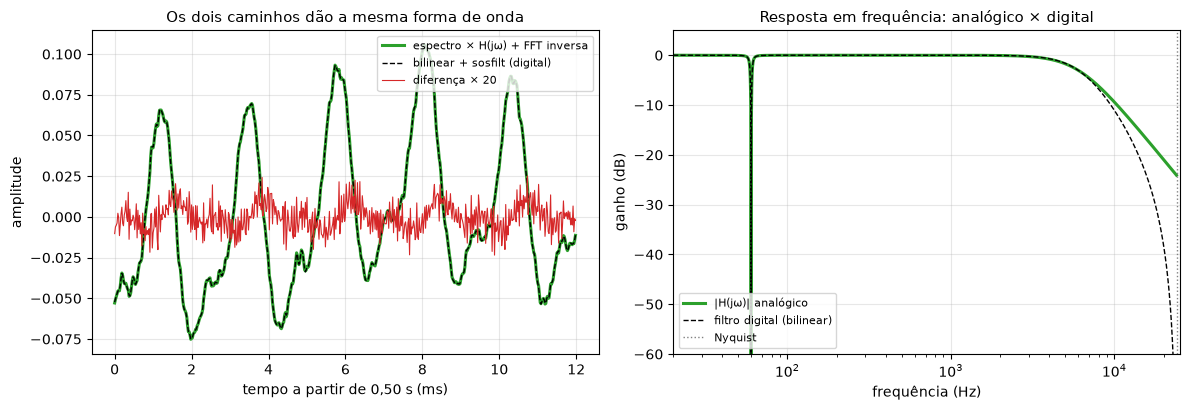

In [27]:
f_resp = np.sort(np.append(np.geomspace(20, fs / 2 * 0.999, 4000), F_REDE))
_, h_dig = signal.sosfreqz(sos, worN=f_resp, fs=fs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
T_JAN = 0.50
jan = slice(int(T_JAN * fs), int(T_JAN * fs) + int(0.012 * fs))
ax1.plot(1e3 * (t_s[jan] - T_JAN), y_filtrado[jan], color=COR["filtrado"], lw=2.2,
         label="espectro × H(jω) + FFT inversa")
ax1.plot(1e3 * (t_s[jan] - T_JAN), y_sosfilt[jan], "k--", lw=1.0, label="bilinear + sosfilt (digital)")
ax1.plot(1e3 * (t_s[jan] - T_JAN), 20 * (y_filtrado[jan] - y_sosfilt[jan]), color=COR["ruidoso"], lw=0.8,
         label="diferença × 20")
ax1.set(xlabel="tempo a partir de 0,50 s (ms)", ylabel="amplitude",
        title="Os dois caminhos dão a mesma forma de onda")
ax1.legend(fontsize=8, loc="upper right")

ax2.semilogx(f_resp, em_db(H_total(f_resp)), color=COR["filtrado"], lw=2.2, label="|H(jω)| analógico")
ax2.semilogx(f_resp, em_db(h_dig), "k--", lw=1.0, label="filtro digital (bilinear)")
ax2.axvline(fs / 2, color="0.5", ls=":", lw=1, label="Nyquist")
ax2.set(xlabel="frequência (Hz)", ylabel="ganho (dB)", ylim=(-60, 5), xlim=(20, fs / 2 * 1.05),
        title="Resposta em frequência: analógico × digital")
ax2.legend(fontsize=8, loc="lower left")
salvar_fig(fig, "fig12_verificacao_cruzada.png")

À esquerda estão 12 ms das duas saídas, uma em cima da outra. A curva verde veio de multiplicar o espectro por $H(j\omega)$ e fazer a FFT inversa. A tracejada preta veio do filtro digital rodando amostra por amostra no tempo. Elas coincidem. A diferença entre as duas, ampliada 20 vezes para dar para ver, é um resíduo pequeno com cara de ruído. Em números: a diferença RMS fica cerca de 40 dB abaixo do sinal na versão causal (`sosfilt`) e mais de 50 dB abaixo na de fase zero (`sosfiltfilt`), com correlação acima de 0,9999 nos dois casos.

Elas não são idênticas, e o gráfico da direita explica o motivo. As duas respostas em frequência são iguais até alguns kHz, mas perto de Nyquist o filtro digital atenua mais que o analógico. Isso vem da transformação bilinear, que espreme o eixo de frequências: ela leva o $f=\infty$ do mundo analógico (onde o passa-baixas tem ganho zero) para $f_s/2$. A diferença, portanto, está em uma região onde só tem ruído já bem atenuado. Em 60 Hz e na faixa da nota os dois filtros são o mesmo.

O que tiro disso é que **filtrar no tempo e filtrar na frequência são a mesma operação**, vista de dois lados. É o teorema da convolução acontecendo na prática.

## 3.4 Antes e depois

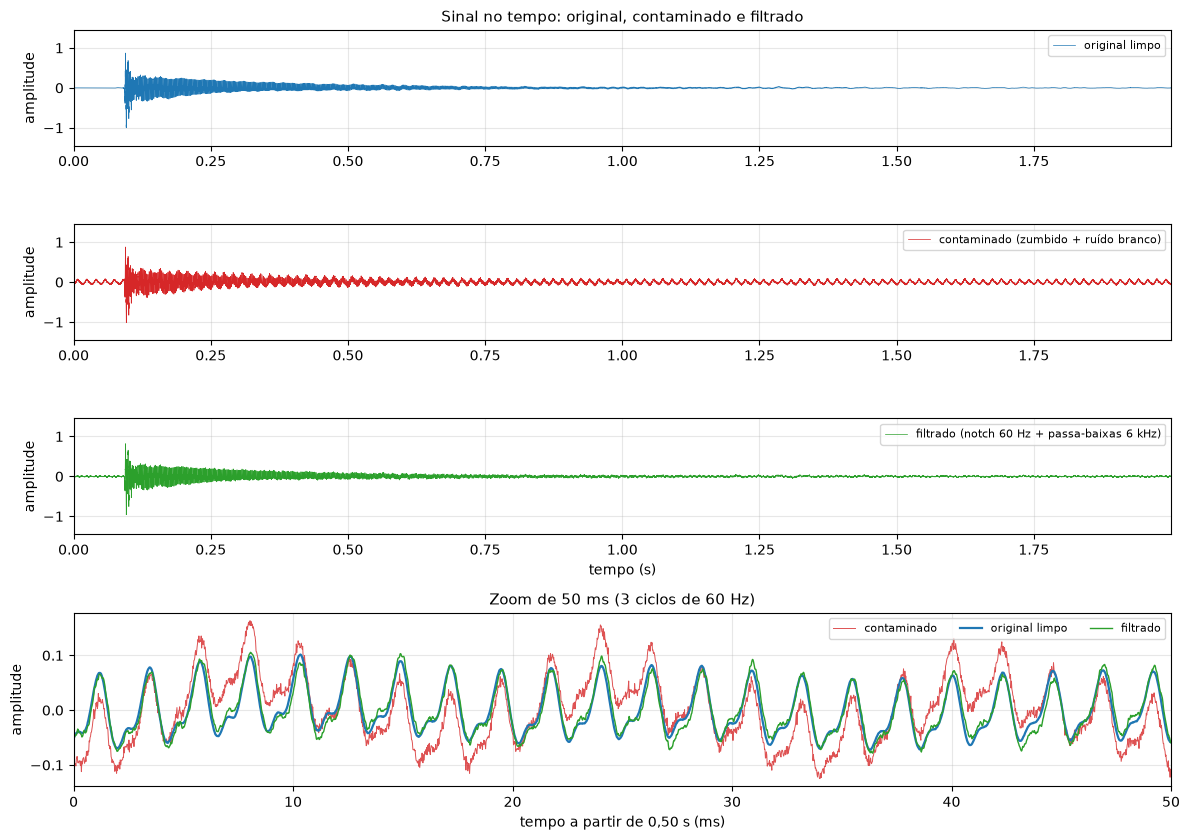

In [28]:
def painel_tempo(ax, x, cor, rotulo, intervalo):
    """Desenha um sinal no tempo em um eixo, com rótulo e limites padronizados."""
    ax.plot(t_s[intervalo], x[intervalo], color=cor, lw=0.5, label=rotulo)
    ax.set_ylabel("amplitude")
    ax.set_ylim(-1.45, 1.45)
    ax.legend(loc="upper right", fontsize=8)


fig = plt.figure(figsize=(12, 8.5))
grade = fig.add_gridspec(4, 1, height_ratios=[1, 1, 1, 1.5])
versoes = [(x_limpo, COR["original"], "original limpo"),
           (x_ruidoso, COR["ruidoso"], "contaminado (zumbido + ruído branco)"),
           (y_filtrado, COR["filtrado"], "filtrado (notch 60 Hz + passa-baixas 6 kHz)")]
tudo = slice(0, len(t_s))
for i, (x, cor, rotulo) in enumerate(versoes):
    ax = fig.add_subplot(grade[i])
    painel_tempo(ax, x, cor, rotulo, tudo)
    ax.set_xlim(0, t_s[-1])
    if i == 0:
        ax.set_title("Sinal no tempo: original, contaminado e filtrado")
ax.set_xlabel("tempo (s)")

axz = fig.add_subplot(grade[3])
T_ZOOM = 0.50
jz = slice(int(T_ZOOM * fs), int((T_ZOOM + 0.05) * fs))
axz.plot(1e3 * (t_s[jz] - T_ZOOM), x_ruidoso[jz], color=COR["ruidoso"], lw=0.7, alpha=0.8, label="contaminado")
axz.plot(1e3 * (t_s[jz] - T_ZOOM), x_limpo[jz], color=COR["original"], lw=1.6, label="original limpo")
axz.plot(1e3 * (t_s[jz] - T_ZOOM), y_filtrado[jz], color=COR["filtrado"], lw=1.0, label="filtrado")
axz.set(xlabel="tempo a partir de 0,50 s (ms)", ylabel="amplitude", xlim=(0, 50),
        title="Zoom de 50 ms (3 ciclos de 60 Hz)")
axz.legend(loc="upper right", fontsize=8, ncol=3)
salvar_fig(fig, "fig13_antes_depois_tempo.png")

**O que se vê no tempo.** No sinal contaminado, o zumbido forma uma faixa de amplitude constante que atravessa a figura inteira, inclusive o silêncio antes do ataque. Como o zumbido não decai e a nota decai, a situação piora com o tempo: de $\sim$1 s em diante o que se vê (e se ouve) é quase só zumbido e chiado.

No sinal filtrado essa faixa some e o formato de ataque e decaimento volta, bem parecido com o original. No final ainda dá para ver um resto de ruído.

O zoom mostra o mecanismo. No contaminado, a nota (a oscilação rápida de $\approx$2,28 ms) aparece "montada" em uma onda lenta com período de 16,7 ms, que é o zumbido de 60 Hz, e engrossada pelo ruído branco. Depois do filtro a onda lenta desaparece e a curva verde volta a andar junto com a azul. Elas não ficam idênticas: sobra uma ondulação pequena, que são os harmônicos de 120 e 180 Hz do zumbido, um pouco de ruído fino e um pequeno atraso em relação ao original, causado pela fase do filtro.

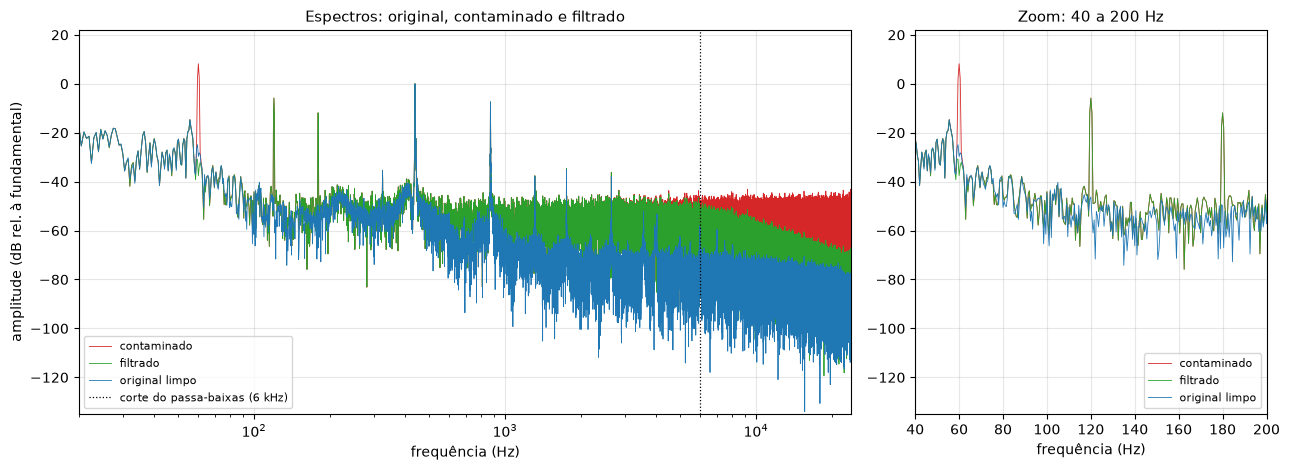

In [29]:
_, amp_filtrado = espectro(y_filtrado, fs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [2.2, 1]})
for ax in (ax1, ax2):
    ax.plot(f_c[1:], em_db(amp_ruidoso[1:], ref5), color=COR["ruidoso"], lw=0.6, label="contaminado")
    ax.plot(f_c[1:], em_db(amp_filtrado[1:], ref5), color=COR["filtrado"], lw=0.6, label="filtrado")
    ax.plot(f_c[1:], em_db(amp_limpo[1:], ref5), color=COR["original"], lw=0.6, label="original limpo")
    ax.set_xlabel("frequência (Hz)")
ax1.set_xscale("log")
ax1.axvline(FC_PB, color="k", ls=":", lw=0.9, label=f"corte do passa-baixas ({FC_PB / 1e3:.0f} kHz)")
ax1.set(xlim=(20, fs / 2), ylim=(-135, 22), ylabel="amplitude (dB rel. à fundamental)",
        title="Espectros: original, contaminado e filtrado")
ax1.legend(loc="lower left", fontsize=8)
ax2.set(xlim=(40, 200), ylim=(-135, 22), title="Zoom: 40 a 200 Hz")
ax2.legend(loc="lower right", fontsize=8)
salvar_fig(fig, "fig14_antes_depois_frequencia.png")

**O que se vê na frequência.** Aqui o resultado do filtro fica bem mais fácil de ler do que no tempo.

Em 60 Hz, a linha mais alta do espectro contaminado desaparece. No zoom dá para ver que no lugar dela ficou um vale estreito, um pouco mais fundo até que o original, porque o notch tira também o pouco de ruído grave legítimo que existia entre 59 e 61 Hz.

Em 120 e 180 Hz as duas linhas continuam lá, com a mesma altura. O filtro não foi feito para elas.

Nos harmônicos da nota, entre 438 Hz e 2,65 kHz, a curva verde e a azul coincidem nos picos. O que era música passou sem alteração.

Acima de 6 kHz o piso do sinal filtrado vai caindo em relação ao contaminado, 12 dB por oitava, que é a inclinação de um passa-baixas de 2ª ordem.

Entre os harmônicos, abaixo de 6 kHz, a curva verde continua colada na vermelha, bem acima da azul. Esse ruído está na mesma faixa do sinal, e o filtro não tem como saber o que é um e o que é outro.

## 3.5 Medidas: SNR e erro RMS

Como tenho o original limpo, o "ruído" de qualquer versão é simplesmente a diferença em relação a ele: $e[k]=y[k]-x_{limpo}[k]$. Daí

$$\mathrm{SNR}=10\log_{10}\frac{P_{x_{limpo}}}{P_e},\qquad \mathrm{RMSE}=\sqrt{\frac{1}{N}\sum_k e[k]^2}.$$

In [30]:
def linha_metricas(nome, y):
    """SNR (dB) e erro RMS de y em relação ao original limpo."""
    return {"sinal": nome, "SNR (dB)": snr_db(x_limpo, y), "erro RMS": np.sqrt(potencia(y - x_limpo))}


tabela_metricas = pd.DataFrame([
    linha_metricas("contaminado (antes)", x_ruidoso),
    linha_metricas("só notch, causal", y_so_notch),
    linha_metricas("notch + passa-baixas, causal  [filtrado.wav]", y_filtrado),
    linha_metricas("notch + passa-baixas, fase zero", y_fase_zero),
])
tabela_metricas["ganho de SNR (dB)"] = tabela_metricas["SNR (dB)"] - tabela_metricas["SNR (dB)"].iloc[0]
display(tabela_metricas.style.format({"SNR (dB)": "{:.2f}", "erro RMS": "{:.4f}",
                                      "ganho de SNR (dB)": "{:+.2f}"}).hide(axis="index"))

sinal,SNR (dB),erro RMS,ganho de SNR (dB)
contaminado (antes),2.91,0.0387,+0.00
"só notch, causal",14.66,0.0100,+11.75
"notch + passa-baixas, causal [filtrado.wav]",12.09,0.0135,+9.18
"notch + passa-baixas, fase zero",15.49,0.0091,+12.57


In [31]:
def erro_por_faixa(y):
    """Reparte a potência do erro (y - original) por faixas, em % da potência do sinal limpo."""
    e = y - x_limpo
    faixas = {"59–61 Hz (zumbido principal)": [(59, 61)],
              "119–121 e 179–181 Hz (harmônicos do zumbido)": [(119, 121), (179, 181)],
              f"acima de {FC_PB / 1e3:.0f} kHz": [(FC_PB, fs / 2 + 1)]}
    saida = {nome: sum(potencia_na_faixa(e, fs, a, b) for a, b in lims) for nome, lims in faixas.items()}
    saida[f"restante abaixo de {FC_PB / 1e3:.0f} kHz (faixa da música)"] = potencia(e) - sum(saida.values())
    return {nome: 100 * p / potencia(x_limpo) for nome, p in saida.items()}


tabela_erro = pd.DataFrame({"contaminado": erro_por_faixa(x_ruidoso),
                            "filtrado (causal)": erro_por_faixa(y_filtrado),
                            "filtrado (fase zero)": erro_por_faixa(y_fase_zero)})
tabela_erro.loc["TOTAL"] = tabela_erro.sum()
print("Potência do erro em cada faixa, em % da potência do sinal limpo:")
display(tabela_erro.style.format("{:.3f}"))

Potência do erro em cada faixa, em % da potência do sinal limpo:


,contaminado,filtrado (causal),filtrado (fase zero)
59–61 Hz (zumbido principal),47.765,0.017,0.012
119–121 e 179–181 Hz (harmônicos do zumbido),2.371,2.369,2.369
acima de 6 kHz,0.752,0.586,0.194
restante abaixo de 6 kHz (faixa da música),0.248,3.208,0.252
TOTAL,51.135,6.180,2.827


**O que os números dizem**

Antes do filtro a SNR era de $2{,}9$ dB. O erro tinha metade da potência do sinal (51%), e quase tudo isso (47,8% da potência do sinal) estava entre 59 e 61 Hz.

Só o notch já resolve quase tudo: a SNR vai para $14{,}7$ dB, um ganho de $11{,}8$ dB. Ele ataca justamente a parcela onde o erro estava concentrado, e por isso um filtro tão simples dá tanto resultado.

Com notch e passa-baixas em fase zero cheguei a $15{,}5$ dB ($+12{,}6$ dB). A potência do erro caiu de 51% para 2,8% da potência do sinal, umas 18 vezes menos. O passa-baixas contribui com menos de 1 dB. Ele reduz o ruído acima de 6 kHz para cerca de um quarto, mas essa parcela já era pequena perto do que sobrou em 120 e 180 Hz. O efeito dele se percebe mais ouvindo (o chiado fica menos agudo) do que neste número.

O resultado que me confundiu foi o do filtro causal, que é o `filtrado.wav`: $12{,}1$ dB, **menos** que o notch sozinho. À primeira vista parece que o passa-baixas piorou o sinal, o que não faz sentido, porque o ruído que sobra é o mesmo da versão de fase zero e as duas soam iguais. A explicação está na tabela de erro por faixa: a linha "restante abaixo de 6 kHz" vale 3,2% na versão causal e 0,25% na de fase zero. O passa-baixas causal **atrasa** o sinal em algumas dezenas de microssegundos (menos de 2 amostras). Como calculei a SNR subtraindo um sinal do outro ponto a ponto, esse desalinhamento mínimo entra na conta como se fosse erro. O ouvido não percebe um atraso constante desse tamanho.

Ficou a lição sobre a métrica: SNR por diferença de formas de onda mede fidelidade *de forma de onda*, e é sensível à fase. Para comparar filtros com fases diferentes, a versão de fase zero mostra de forma mais justa quanto ruído realmente sobrou.

**O que o filtro NÃO recuperou.**

1. **Os harmônicos do zumbido em 120 e 180 Hz.** O notch de 2ª ordem tem um único par de zeros e só anula 60 Hz. Depois da filtragem eles passam a ser a maior parte do erro (2,4% da potência do sinal, de um total de 2,8%) e são o que limita a SNR final. Para tirá-los seriam necessários mais dois notches em cascata (um filtro "pente"), ao custo de mais dois blocos de 2ª ordem.
2. **O ruído branco dentro da faixa da nota (abaixo de 6 kHz).** Ele ocupa as mesmas frequências do sinal. Qualquer filtro linear que o atenuasse atenuaria a música junto. O passa-baixas só resolve a parte do ruído que está onde a música não está.
3. **Uma fatia do próprio sinal entre 59 e 61 Hz.** O notch não distingue zumbido de conteúdo legítimo nessa faixa. Nesta gravação a perda não importa (ali só havia ruído grave), mas em uma nota com harmônico perto de 60 Hz seria um problema de verdade.
4. **O final da nota.** O ruído que sobra tem nível constante e a nota decai. Depois de $\sim$1 s a SNR local é bem pior que a média, e o chiado volta a aparecer.

## 3.6 Áudios para ouvir

Os três sinais são salvos em `outputs/audio/` com a mesma $f_s$ e com **o mesmo ganho** (o fator é escolhido para que o maior pico entre os três fique em $-1$ dBFS). Assim nenhum arquivo sofre *clipping* e a comparação de volume entre eles continua honesta: se cada arquivo fosse normalizado sozinho, o original soaria artificialmente mais alto que o contaminado.

In [32]:
def salvar_wav(caminho, x, fs, ganho):
    """Salva x em PCM de 16 bits aplicando um ganho comum; confere que não há clipping."""
    y = ganho * x
    assert np.max(np.abs(y)) < 1.0, "clipping!"
    wavfile.write(caminho, fs, np.round(y * 32767).astype(np.int16))


audios = {"original.wav": x_limpo, "ruidoso.wav": x_ruidoso, "filtrado.wav": y_filtrado}
pico_global = max(np.max(np.abs(x)) for x in audios.values())
GANHO_COMUM = 10 ** (-1 / 20) / pico_global          # maior pico dos três em -1 dBFS
for nome, x in audios.items():
    salvar_wav(DIR_AUDIO / nome, x, fs, GANHO_COMUM)
    print(f"{nome:13s} fs = {fs} Hz | pico = {20 * np.log10(GANHO_COMUM * np.max(np.abs(x))):6.2f} dBFS | "
          f"RMS = {20 * np.log10(GANHO_COMUM * np.sqrt(potencia(x))):6.2f} dBFS")

original.wav  fs = 48000 Hz | pico =  -1.12 dBFS | RMS = -26.44 dBFS
ruidoso.wav   fs = 48000 Hz | pico =  -1.00 dBFS | RMS = -24.65 dBFS
filtrado.wav  fs = 48000 Hz | pico =  -1.48 dBFS | RMS = -26.36 dBFS


In [33]:
for nome, titulo in [("original.wav", "1) Original limpo"), ("ruidoso.wav", "2) Contaminado (zumbido de 60 Hz + ruído branco)"),
                     ("filtrado.wav", "3) Filtrado (notch 60 Hz + passa-baixas 6 kHz)")]:
    print(titulo)
    display(Audio(filename=str(DIR_AUDIO / nome)))

1) Original limpo


2) Contaminado (zumbido de 60 Hz + ruído branco)


3) Filtrado (notch 60 Hz + passa-baixas 6 kHz)


**O que se ouve.** No áudio contaminado, um zumbido grave e contínuo toma conta, junto com um chiado, e a nota do violão fica lá atrás. No filtrado, o zumbido grave principal some e o chiado fica mais abafado, porque perdeu a parte mais aguda.

Ouvindo com atenção, de preferência com fone e prestando atenção no fim da nota, ainda dá para perceber um resto de zumbido mais agudo (120 e 180 Hz) e um chiado suave. São exatamente os itens 1 e 2 da lista do que o filtro não recuperou. Já o timbre do violão não muda de forma perceptível entre o original e o filtrado, o que é coerente com um filtro de ganho $\approx 1$ em todos os harmônicos que importam.

<a id="etapa4"></a>
# Etapa 4 — O filtro como sistema linear

Na Etapa 3 o filtro foi tratado como uma curva $H(j\omega)$ que multiplica o espectro. Agora olho para ele como um **sistema físico**: um circuito descrito por uma equação diferencial. A ferramenta que liga as duas visões é a **Transformada de Laplace**,

$$\mathcal{L}\{y(t)\}=Y(s)=\int_0^\infty y(t)\,e^{-st}\,dt,\qquad s=\sigma+j\omega,$$

cuja propriedade central é transformar derivadas em multiplicações por $s$: $\mathcal{L}\{y'\}=sY(s)-y(0)$. Com condições iniciais nulas, uma equação diferencial linear vira uma equação algébrica, e a razão $H(s)=Y(s)/X(s)$ é a **função de transferência** do sistema.

## 4.1 Aquecimento: filtro RC de 1ª ordem

Um resistor $R$ em série com um capacitor $C$, com a saída $y(t)$ tomada sobre o capacitor e a entrada $x(t)$ aplicada ao conjunto. A corrente é $i=C\,y'$ e a lei das malhas dá

$$RC\,\frac{dy}{dt}+y(t)=x(t).$$

In [34]:
t = sp.symbols("t", nonnegative=True)
s = sp.symbols("s")
omega = sp.symbols("omega", real=True, positive=True)
R, C, w0_s, Q_s, wc_s = sp.symbols("R C omega_0 Q omega_c", positive=True)
x_f, y_f = sp.Function("x"), sp.Function("y")
X_s, Y_s = sp.symbols("X Y")


def laplace_da_edo(edo):
    """Aplica a Transformada de Laplace aos dois lados de uma EDO linear (devolve lado esq. - lado dir.)."""
    return sp.laplace_transform(edo.lhs - edo.rhs, t, s, noconds=True)


def funcao_de_transferencia(edo):
    """Obtém H(s) = Y(s)/X(s) de uma EDO linear, com condições iniciais nulas."""
    transformada = laplace_da_edo(edo)
    iniciais = {x_f(0): 0, y_f(0): 0,
                sp.Subs(sp.Derivative(x_f(t), t), t, 0): 0,
                sp.Subs(sp.Derivative(y_f(t), t), t, 0): 0}
    algebrica = transformada.subs(iniciais).subs({sp.LaplaceTransform(y_f(t), t, s): Y_s,
                                                  sp.LaplaceTransform(x_f(t), t, s): X_s})
    return sp.simplify(sp.solve(algebrica, Y_s)[0] / X_s)


edo_rc = sp.Eq(R * C * y_f(t).diff(t) + y_f(t), x_f(t))
display(Math(r"\text{EDO: }\;" + sp.latex(edo_rc)))
display(Math(r"\mathcal{L}\{\text{EDO}\}=0:\;\;" + sp.latex(laplace_da_edo(edo_rc)) + "=0"))
H_rc = funcao_de_transferencia(edo_rc)
polo_rc = sp.solve(sp.denom(H_rc), s)[0]
h_rc = sp.inverse_laplace_transform(H_rc, s, t)
mod_rc = sp.simplify(sp.Abs(H_rc.subs(s, sp.I * omega)))
display(Math(r"H_{RC}(s)=\frac{Y(s)}{X(s)}=" + sp.latex(H_rc)))
display(Math(r"\text{polo: } s=" + sp.latex(polo_rc) + r"\qquad h(t)=\mathcal{L}^{-1}\{H\}=" + sp.latex(h_rc)))
display(Math(r"|H_{RC}(j\omega)|=" + sp.latex(mod_rc)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

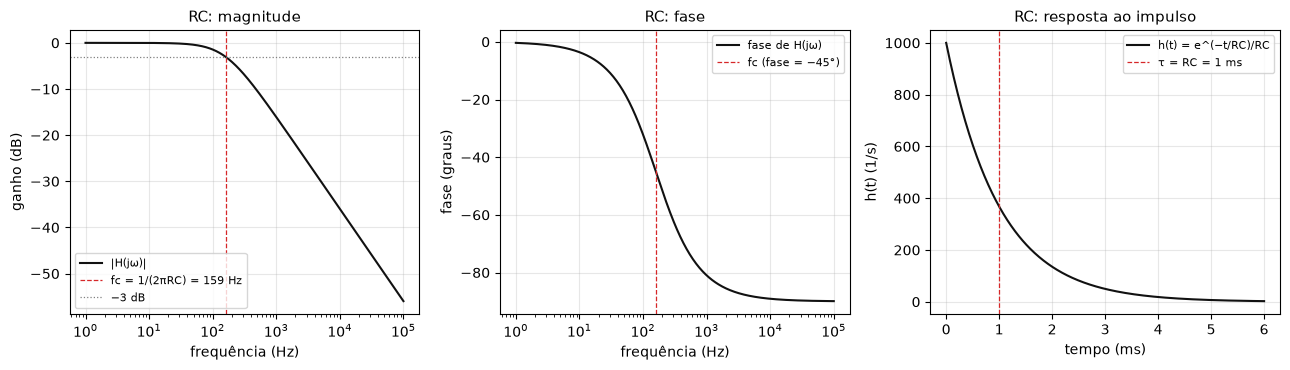

In [35]:
R_EX, C_EX = 1e3, 1e-6                                   # exemplo: 1 kΩ e 1 µF -> RC = 1 ms
fc_rc = 1 / (2 * np.pi * R_EX * C_EX)
f_rc = np.geomspace(1, 1e5, 500)
_, resp_rc = signal.freqs([1], [R_EX * C_EX, 1], worN=2 * np.pi * f_rc)
t_rc, h_rc_num = signal.impulse(([1], [R_EX * C_EX, 1]), T=np.linspace(0, 6e-3, 500))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.8))
ax1.semilogx(f_rc, em_db(resp_rc), color=COR["filtro"], label="|H(jω)|")
ax1.axvline(fc_rc, color=COR["ruidoso"], ls="--", lw=0.9, label=f"fc = 1/(2πRC) = {fc_rc:.0f} Hz")
ax1.axhline(-3.01, color="0.5", ls=":", lw=0.9, label="−3 dB")
ax1.set(xlabel="frequência (Hz)", ylabel="ganho (dB)", title="RC: magnitude")
ax1.legend(fontsize=8)
ax2.semilogx(f_rc, np.degrees(np.angle(resp_rc)), color=COR["filtro"], label="fase de H(jω)")
ax2.axvline(fc_rc, color=COR["ruidoso"], ls="--", lw=0.9, label="fc (fase = −45°)")
ax2.set(xlabel="frequência (Hz)", ylabel="fase (graus)", title="RC: fase")
ax2.legend(fontsize=8)
ax3.plot(1e3 * t_rc, h_rc_num, color=COR["filtro"], label="h(t) = e^(−t/RC)/RC")
ax3.axvline(1e3 * R_EX * C_EX, color=COR["ruidoso"], ls="--", lw=0.9, label="τ = RC = 1 ms")
ax3.set(xlabel="tempo (ms)", ylabel="h(t) (1/s)", title="RC: resposta ao impulso")
ax3.legend(fontsize=8)
salvar_fig(fig, "fig15_rc_primeira_ordem.png")

O RC é pequeno, mas já tem dentro dele todos os passos que vou repetir com o filtro de verdade.

Primeiro, da equação diferencial para $H(s)$. A derivada virou o fator $s$, a equação virou $RC\,sY+Y=X$, e dali sai $H(s)=\dfrac{1}{1+RCs}$, como o enunciado antecipava.

Depois, o polo e a estabilidade. $H$ tem um único polo, em $s=-1/RC$, real e **negativo**. A transformada inversa mostra o que isso significa no tempo: $h(t)=\frac{1}{RC}e^{-t/RC}$, uma exponencial que **decai** (gráfico da direita). A parte real do polo é a taxa de decaimento. Se o polo estivesse em $s>0$, a exponencial cresceria sem parar e o sistema seria instável.

Por fim, a resposta em frequência. Trocando $s$ por $j\omega$ chega-se a $|H(j\omega)|=1/\sqrt{1+(\omega RC)^2}$. Em baixas frequências o ganho é 1, e a partir de $f_c=1/(2\pi RC)$ (uns 159 Hz no exemplo) ele cai 20 dB por década. É um passa-baixas. O detalhe de que mais gostei é que $\omega=1/RC$ é exatamente a distância do polo até a origem: a posição do polo no plano $s$ marca o ponto onde a curva dobra no eixo de frequências.

Com isso entendido, passo para o filtro que usei de fato.

## 4.2 O filtro da Etapa 3: notch de 2ª ordem

**Equação diferencial.** Um circuito que realiza o notch é o **RLC série com a saída tomada sobre o conjunto L+C**. Em $\omega_0=1/\sqrt{LC}$ as tensões no indutor e no capacitor se cancelam (ressonância série), a tensão sobre L+C se anula e a entrada não chega à saída. Escrevendo as leis de Kirchhoff e eliminando a corrente, chega-se a

$$\frac{d^2y}{dt^2}+\frac{\omega_0}{Q}\frac{dy}{dt}+\omega_0^2\,y=\frac{d^2x}{dt^2}+\omega_0^2\,x,
\qquad \omega_0=\frac{1}{\sqrt{LC}},\quad Q=\frac{\omega_0L}{R}=\frac{1}{R}\sqrt{\frac{L}{C}} .$$

Repare que o lado direito também tem derivadas da entrada: são elas que criarão os **zeros**.

**Passa-baixas Butterworth de 2ª ordem** (por exemplo, um RLC série com saída no capacitor e $Q=1/\sqrt2$):

$$\frac{1}{\omega_c^2}\frac{d^2y}{dt^2}+\frac{\sqrt2}{\omega_c}\frac{dy}{dt}+y=x .$$

Aplico `laplace_transform` às duas equações.

In [36]:
edo_notch = sp.Eq(y_f(t).diff(t, 2) + w0_s / Q_s * y_f(t).diff(t) + w0_s ** 2 * y_f(t),
                  x_f(t).diff(t, 2) + w0_s ** 2 * x_f(t))
edo_pb = sp.Eq(y_f(t).diff(t, 2) / wc_s ** 2 + sp.sqrt(2) / wc_s * y_f(t).diff(t) + y_f(t), x_f(t))

display(Math(r"\mathcal{L}\{\text{EDO do notch}\}=0:\;\;" + sp.latex(laplace_da_edo(edo_notch)) + "=0"))


def forma_padrao(H):
    """Escreve H(s) como razão de polinômios em s com coeficiente líder 1 no denominador."""
    num, den = sp.fraction(sp.together(H))
    lider = sp.Poly(den, s).LC()
    return sp.collect(sp.expand(num / lider), s) / sp.collect(sp.expand(den / lider), s)


H_notch_s = forma_padrao(funcao_de_transferencia(edo_notch))
H_pb_s = forma_padrao(funcao_de_transferencia(edo_pb))
H_total_s = H_notch_s * H_pb_s                    # cascata: produto das funções de transferência
display(Math(r"H_{notch}(s)=" + sp.latex(H_notch_s)))
display(Math(r"H_{pb}(s)=" + sp.latex(H_pb_s)))
display(Math(r"H(s)=H_{notch}(s)\,H_{pb}(s)=" + sp.latex(H_total_s)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Com condições iniciais nulas, cada derivada vira uma potência de $s$, e a EDO do notch se transforma em $(s^2+\frac{\omega_0}{Q}s+\omega_0^2)\,Y=(s^2+\omega_0^2)\,X$. Dividindo um lado pelo outro:

$$H_{notch}(s)=\frac{s^2+\omega_0^2}{s^2+\dfrac{\omega_0}{Q}s+\omega_0^2}.$$

É exatamente a expressão que usei na Etapa 3, agora obtida a partir do circuito. Vale reparar em como a conta se organiza: o lado esquerdo da EDO (as derivadas da saída) virou o **denominador**, e o lado direito (as derivadas da entrada) virou o **numerador**.

Sobre a cascata: ligar dois sistemas em série quer dizer que a saída do primeiro é a entrada do segundo, $Y=H_{pb}\cdot(H_{notch}\cdot X)$. No domínio de Laplace isso é uma simples **multiplicação**, $H=H_{notch}H_{pb}$. No tempo seria a convolução das duas respostas ao impulso, bem mais trabalhosa. Os polos e zeros do conjunto são os de cada bloco reunidos, então o filtro total tem 2 zeros e 4 polos.

## 4.3 Polos e zeros

**Zeros** são os valores de $s$ que anulam o numerador ($H=0$: a saída é nula); **polos** são os que anulam o denominador ($H\to\infty$). Calculo simbolicamente com o `sympy` e depois confiro numericamente com `scipy.signal.tf2zpk`.

In [37]:
zeros_notch = sp.solve(sp.numer(sp.together(H_notch_s)), s)
polos_notch = sp.solve(sp.denom(sp.together(H_notch_s)), s)
polos_pb = sp.solve(sp.denom(sp.together(H_pb_s)), s)
display(Math(r"\text{zeros do notch: } s=" + sp.latex(zeros_notch)))
display(Math(r"\text{polos do notch: } s=" + sp.latex([sp.simplify(p) for p in polos_notch])))
display(Math(r"\text{polos do passa-baixas: } s=" + sp.latex([sp.simplify(p) for p in polos_pb])))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [38]:
valores = {w0_s: 2 * sp.pi * F_REDE, Q_s: Q_NOTCH, wc_s: 2 * sp.pi * FC_PB}


def para_complexos(raizes):
    """Substitui os parâmetros numéricos nas raízes simbólicas e ordena o resultado."""
    return np.array(sorted((complex(r.subs(valores).evalf()) for r in raizes),
                           key=lambda z: (round(z.real, 6), z.imag)))


def coeficientes_numericos(H):
    """Coeficientes (num, den) de H(s) em potências decrescentes de s, já com os valores numéricos."""
    num, den = sp.fraction(sp.together(H.subs(valores)))
    return (np.array(sp.Poly(sp.expand(num), s).all_coeffs(), dtype=float),
            np.array(sp.Poly(sp.expand(den), s).all_coeffs(), dtype=float))


b_tot, a_tot = coeficientes_numericos(H_total_s)
b_tot, a_tot = b_tot / a_tot[0], a_tot / a_tot[0]
zeros_scipy, polos_scipy, _ = signal.tf2zpk(b_tot, a_tot)
ordenar = lambda v: np.array(sorted(v, key=lambda z: (round(z.real, 6), z.imag)))

zeros_sym = para_complexos(zeros_notch)
polos_sym = para_complexos(polos_notch + polos_pb)
tabela_pz = pd.DataFrame({
    "tipo": ["zero"] * 2 + ["polo"] * 4,
    "bloco": ["notch"] * 2 + ["passa-baixas"] * 2 + ["notch"] * 2,
    "sympy (rad/s)": np.concatenate([zeros_sym, polos_sym]),
    "tf2zpk (rad/s)": np.concatenate([ordenar(zeros_scipy), ordenar(polos_scipy)]),
})
tabela_pz["|diferença| relativa"] = (np.abs(tabela_pz["sympy (rad/s)"] - tabela_pz["tf2zpk (rad/s)"])
                                     / np.abs(tabela_pz["sympy (rad/s)"]))
tabela_pz["parte real (rad/s)"] = np.real(tabela_pz["sympy (rad/s)"])
tabela_pz["|parte imag.|/2π (Hz)"] = np.abs(np.imag(tabela_pz["sympy (rad/s)"])) / (2 * np.pi)
display(tabela_pz.style.format({"sympy (rad/s)": "{:.3f}", "tf2zpk (rad/s)": "{:.3f}",
                                "|diferença| relativa": "{:.1e}", "parte real (rad/s)": "{:.3f}",
                                "|parte imag.|/2π (Hz)": "{:.3f}"}).hide(axis="index"))

sigma_notch = W0 / (2 * Q_NOTCH)
print(f"Notch: polos em -{sigma_notch:.3f} ± j{W0 * np.sqrt(1 - 1 / (4 * Q_NOTCH ** 2)):.3f} rad/s; "
      f"zeros em ± j{W0:.3f} rad/s")
print(f"Distância dos polos do notch ao eixo jω: ω0/(2Q) = {sigma_notch:.3f} rad/s "
      f"= {sigma_notch / (2 * np.pi):.2f} Hz  (metade da banda rejeitada de {F_REDE / Q_NOTCH:.0f} Hz)")

tipo,bloco,sympy (rad/s),tf2zpk (rad/s),|diferença| relativa,parte real (rad/s),|parte imag.|/2π (Hz)
zero,notch,0.000-376.991j,0.000-376.991j,0.0e+00,0.000,60.000
zero,notch,0.000+376.991j,-0.000+376.991j,0.0e+00,0.000,60.000
polo,passa-baixas,-26657.298-26657.298j,-26657.298-26657.298j,4.3e-16,-26657.298,4242.641
polo,passa-baixas,-26657.298+26657.298j,-26657.298+26657.298j,4.3e-16,-26657.298,4242.641
polo,notch,-6.283-376.939j,-6.283-376.939j,8.0e-16,-6.283,59.992
polo,notch,-6.283+376.939j,-6.283+376.939j,8.0e-16,-6.283,59.992


Notch: polos em -6.283 ± j376.939 rad/s; zeros em ± j376.991 rad/s
Distância dos polos do notch ao eixo jω: ω0/(2Q) = 6.283 rad/s = 1.00 Hz  (metade da banda rejeitada de 2 Hz)


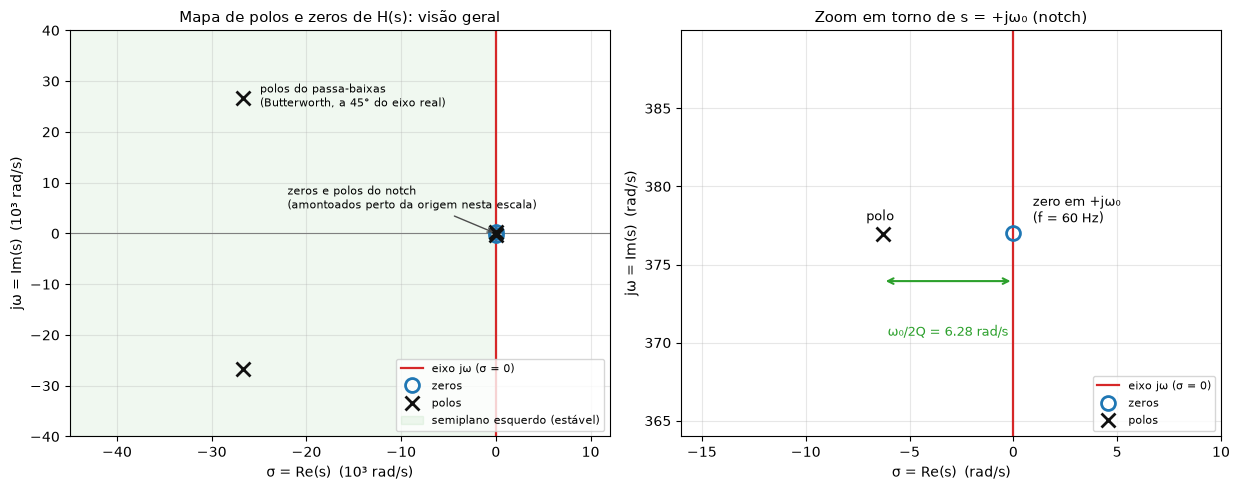

In [39]:
def desenhar_polos_zeros(ax, zeros, polos, escala=1.0):
    """Desenha zeros (círculos) e polos (xis) no plano s, destacando o eixo jω."""
    ax.axvline(0, color=COR["ruidoso"], lw=1.6, label="eixo jω (σ = 0)")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.plot(np.real(zeros) / escala, np.imag(zeros) / escala, "o", ms=10, mfc="none", mec=COR["original"],
            mew=2, label="zeros")
    ax.plot(np.real(polos) / escala, np.imag(polos) / escala, "x", ms=10, color=COR["filtro"], mew=2,
            label="polos")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5))
desenhar_polos_zeros(ax1, zeros_sym, polos_sym, escala=1e3)
ax1.axvspan(-45, 0, color=COR["filtrado"], alpha=0.07, label="semiplano esquerdo (estável)")
ax1.annotate("polos do passa-baixas\n(Butterworth, a 45° do eixo real)", (polos_sym[0].real / 1e3, polos_sym[1].imag / 1e3),
             textcoords="offset points", xytext=(12, -6), fontsize=8)
ax1.annotate("zeros e polos do notch\n(amontoados perto da origem nesta escala)", (0, 0),
             textcoords="offset points", xytext=(-150, 18), fontsize=8,
             arrowprops={"arrowstyle": "->", "color": "0.3"})
ax1.set(xlim=(-45, 12), ylim=(-40, 40), xlabel="σ = Re(s)  (10³ rad/s)", ylabel="jω = Im(s)  (10³ rad/s)",
        title="Mapa de polos e zeros de H(s): visão geral")
ax1.legend(loc="lower right", fontsize=8)

desenhar_polos_zeros(ax2, zeros_sym, polos_sym)
polo_sup = polos_sym[np.argmin(np.abs(polos_sym - 1j * W0))]
ax2.annotate("", xy=(0, polo_sup.imag - 3), xytext=(polo_sup.real, polo_sup.imag - 3),
             arrowprops={"arrowstyle": "<->", "color": COR["filtrado"], "lw": 1.5})
ax2.text(polo_sup.real / 2, polo_sup.imag - 6.5, f"ω₀/2Q = {sigma_notch:.2f} rad/s", ha="center",
         fontsize=9, color=COR["filtrado"])
ax2.annotate(f"zero em +jω₀\n(f = {F_REDE:.0f} Hz)", (0, W0), textcoords="offset points", xytext=(14, 8), fontsize=9)
ax2.annotate("polo", (polo_sup.real, polo_sup.imag), textcoords="offset points", xytext=(-12, 10), fontsize=9)
ax2.set(xlim=(-16, 10), ylim=(W0 - 13, W0 + 13), xlabel="σ = Re(s)  (rad/s)", ylabel="jω = Im(s)  (rad/s)",
        title="Zoom em torno de s = +jω₀ (notch)")
ax2.legend(loc="lower right", fontsize=8)
salvar_fig(fig, "fig16_polos_zeros.png")

Para começar, a conferência: os polos e zeros calculados simbolicamente coincidem com os que o `tf2zpk` devolve. A diferença relativa é da ordem do erro de arredondamento.

Os **zeros do notch** estão em $s=\pm j\omega_0$, isto é, $\pm j\,376{,}99$ rad/s. Eles ficam **exatamente em cima do eixo $j\omega$**, na altura que corresponde a 60 Hz, e não dependem de $Q$.

Os **polos do notch** estão em $s=-\dfrac{\omega_0}{2Q}\pm j\,\omega_0\sqrt{1-\dfrac{1}{4Q^2}}\approx -6{,}28\pm j\,376{,}94$ rad/s. Ficam quase na mesma altura dos zeros, só que recuados $\omega_0/2Q=6{,}28$ rad/s para dentro do semiplano esquerdo. No zoom (à direita) o polo e o zero aparecem lado a lado. Esse par colado é o que caracteriza um notch.

Os **polos do passa-baixas** estão em $s=\omega_c\,\dfrac{-1\pm j}{\sqrt2}\approx(-26{,}7\pm j\,26{,}7)\times10^3$ rad/s. Ficam sobre uma circunferência de raio $\omega_c$, a 45° do eixo real negativo, que é a disposição típica do Butterworth. Na visão geral (à esquerda) eles estão umas cem vezes mais longe da origem que o notch, tanto que nessa escala o notch vira um ponto. Foi por isso que precisei de dois gráficos.

E o mais importante para a próxima seção: **os quatro polos têm parte real negativa** (região verde).

## 4.4 Estabilidade, resposta ao impulso e resposta ao degrau

Cada polo $p=\sigma+j\omega_d$ contribui para a resposta ao impulso com um termo do tipo $e^{pt}=e^{\sigma t}e^{j\omega_d t}$: uma oscilação na frequência $\omega_d$ (a parte imaginária) com envoltória $e^{\sigma t}$ (a parte real). Se **todas** as partes reais são negativas, todas as envoltórias decaem, a resposta ao impulso é absolutamente integrável e toda entrada limitada produz saída limitada (estabilidade BIBO).

Partes reais dos polos (rad/s): [-2.6657298e+04 -2.6657298e+04 -6.2830000e+00 -6.2830000e+00]
Todos os polos têm parte real negativa? True  ->  sistema ESTÁVEL
Constante de tempo do notch: τ = 2Q/ω0 = 0.159 s
Constante de tempo do passa-baixas: τ = √2/ωc = 37.5 µs


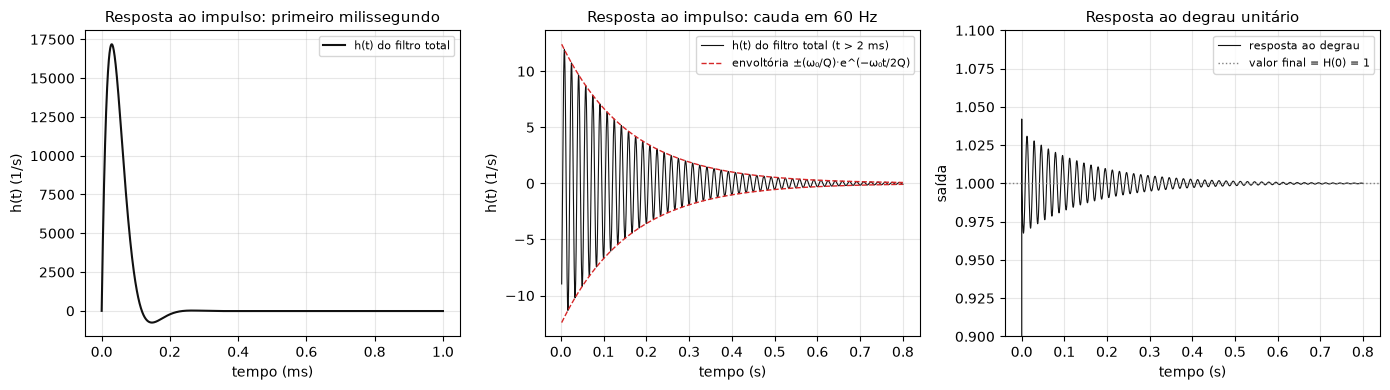

In [40]:
estavel = bool(np.all(polos_sym.real < 0))
print(f"Partes reais dos polos (rad/s): {np.round(polos_sym.real, 3)}")
print(f"Todos os polos têm parte real negativa? {estavel}  ->  sistema {'ESTÁVEL' if estavel else 'INSTÁVEL'}")
print(f"Constante de tempo do notch: τ = 2Q/ω0 = {1 / sigma_notch:.3f} s")
print(f"Constante de tempo do passa-baixas: τ = √2/ωc = {1e6 * np.sqrt(2) / WC:.1f} µs")

sistema = (b_tot, a_tot)
t_curto = np.linspace(0, 1e-3, 2000)                # escala do passa-baixas
t_longo = np.linspace(0, 0.8, 40001)                # escala do notch
_, h_curto = signal.impulse(sistema, T=t_curto)
_, h_longo = signal.impulse(sistema, T=t_longo)
_, degrau = signal.step(sistema, T=t_longo)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
ax1.plot(1e3 * t_curto, h_curto, color=COR["filtro"], label="h(t) do filtro total")
ax1.set(xlabel="tempo (ms)", ylabel="h(t) (1/s)", title="Resposta ao impulso: primeiro milissegundo")
ax1.legend(fontsize=8)

depois = t_longo > 2e-3
ax2.plot(t_longo[depois], h_longo[depois], color=COR["filtro"], lw=0.8, label="h(t) do filtro total (t > 2 ms)")
envolt = (W0 / Q_NOTCH) * np.exp(-sigma_notch * t_longo[depois])
ax2.plot(t_longo[depois], envolt, color=COR["ruidoso"], ls="--", lw=1, label="envoltória ±(ω₀/Q)·e^(−ω₀t/2Q)")
ax2.plot(t_longo[depois], -envolt, color=COR["ruidoso"], ls="--", lw=1)
ax2.set(xlabel="tempo (s)", ylabel="h(t) (1/s)", title="Resposta ao impulso: cauda em 60 Hz")
ax2.legend(fontsize=8, loc="upper right")

ax3.plot(t_longo, degrau, color=COR["filtro"], lw=0.8, label="resposta ao degrau")
ax3.axhline(1.0, color="0.5", ls=":", lw=1, label="valor final = H(0) = 1")
ax3.set(xlabel="tempo (s)", ylabel="saída", ylim=(0.9, 1.1), title="Resposta ao degrau unitário")
ax3.legend(fontsize=8, loc="upper right")
salvar_fig(fig, "fig17_impulso_degrau.png")

O sistema é **estável**, com os quatro polos no semiplano esquerdo. O interessante das respostas no tempo é que dá para ver cada par de polos trabalhando na sua própria escala.

No primeiro milissegundo (à esquerda) aparece um pulso curto e suave, que sobe e desce em frações de milissegundo. É a parte dos polos do passa-baixas, com parte real $-26{,}7\times10^3$ rad/s, ou seja, constante de tempo de uns 37 µs. O passa-baixas "borra" o impulso, e essa é a cara que tem, no tempo, o ato de cortar as altas frequências.

Depois do pulso sobra uma cauda (no centro): uma oscilação fraca em 60 Hz que vai morrendo devagar, acompanhando a envoltória $e^{-\omega_0 t/2Q}$ (tracejada), com constante de tempo $\tau=2Q/\omega_0\approx 0{,}16$ s. São os polos do notch. A parte imaginária deles, $\approx\omega_0$, dá a frequência da oscilação, e a parte real, $-6{,}28$ rad/s, dá a velocidade com que ela some. Como esses polos estão bem perto do eixo $j\omega$, a oscilação demora a morrer. É o preço de um notch estreito: quanto maior o $Q$, mais tempo o filtro fica "ressoando".

Na resposta ao degrau (à direita) a saída vai para 1, porque $H(0)=1$ (o filtro não mexe no nível médio), com uma ondulação de 60 Hz de uns 3% que desaparece no mesmo ritmo.

Se algum polo estivesse à direita do eixo $j\omega$, a envoltória seria uma exponencial crescente. Em cima do eixo, a oscilação nunca morreria. Nos dois casos o filtro não serviria para nada.

## 4.5 Diagrama de Bode

A resposta em frequência é a função de transferência avaliada sobre o eixo imaginário, $H(j\omega)=H(s)\big|_{s=j\omega}$. Calculo de duas maneiras independentes: com `scipy.signal.freqs` a partir dos coeficientes numéricos, e com a expressão **simbólica** de $H(s)$ convertida em função numérica por `sympy.lambdify`. Confiro também contra a função `H_total` que filtrou o sinal na Etapa 3.

máx |freqs − lambdify|        = 6.19e-15
máx |lambdify − H da Etapa 3| = 6.15e-15


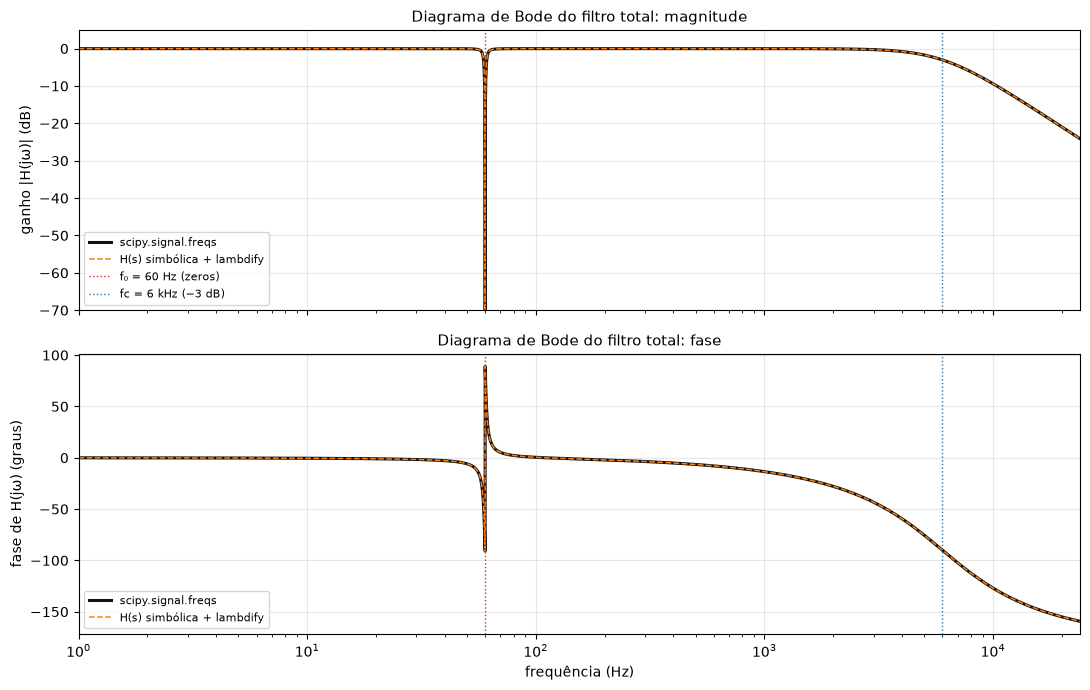

In [41]:
# grade logarítmica + pontos extras bem densos em torno de 60 Hz, para resolver o vale estreito
f_bode = np.unique(np.concatenate([np.geomspace(1, fs / 2, 3000), np.linspace(55, 65, 2001)]))
w_bode = 2 * np.pi * f_bode

_, H_scipy = signal.freqs(b_tot, a_tot, worN=w_bode)
H_lamb = sp.lambdify(s, H_total_s.subs(valores), "numpy")(1j * w_bode)
H_etapa3 = H_total(f_bode)
print(f"máx |freqs − lambdify|        = {np.max(np.abs(H_scipy - H_lamb)):.2e}")
print(f"máx |lambdify − H da Etapa 3| = {np.max(np.abs(H_lamb - H_etapa3)):.2e}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.semilogx(f_bode, em_db(H_scipy), color=COR["filtro"], lw=2.2, label="scipy.signal.freqs")
ax1.semilogx(f_bode, em_db(H_lamb), color="#ff7f0e", ls="--", lw=1.1, label="H(s) simbólica + lambdify")
ax1.axvline(F_REDE, color=COR["ruidoso"], ls=":", lw=1, label="f₀ = 60 Hz (zeros)")
ax1.axvline(FC_PB, color=COR["original"], ls=":", lw=1, label="fc = 6 kHz (−3 dB)")
ax1.set(ylabel="ganho |H(jω)| (dB)", ylim=(-70, 5), title="Diagrama de Bode do filtro total: magnitude")
ax1.legend(fontsize=8, loc="lower left")

ax2.semilogx(f_bode, np.degrees(np.angle(H_scipy)), color=COR["filtro"], lw=2.2, label="scipy.signal.freqs")
ax2.semilogx(f_bode, np.degrees(np.angle(H_lamb)), color="#ff7f0e", ls="--", lw=1.1,
             label="H(s) simbólica + lambdify")
ax2.axvline(F_REDE, color=COR["ruidoso"], ls=":", lw=1)
ax2.axvline(FC_PB, color=COR["original"], ls=":", lw=1)
ax2.set(xlabel="frequência (Hz)", ylabel="fase de H(jω) (graus)", xlim=(1, fs / 2),
        title="Diagrama de Bode do filtro total: fase")
ax2.legend(fontsize=8, loc="lower left")
salvar_fig(fig, "fig18_bode.png")

As duas curvas caem uma em cima da outra. A diferença máxima é da ordem de $10^{-15}$, e o mesmo vale na comparação com a `H_total` que usei para filtrar. Ou seja, a função de transferência que saiu da equação diferencial por Laplace **é** o filtro que apliquei ao espectro na Etapa 3. Não são duas coisas parecidas, são a mesma.

Na magnitude, o ganho é 0 dB (ganho 1) em praticamente toda a faixa, com duas exceções: um vale muito estreito e fundo em 60 Hz, que é o notch, e a queda acima de 6 kHz ($-3$ dB no corte e depois $-40$ dB por década, por serem dois polos). A faixa da nota, de 438 Hz a $\sim$2,7 kHz, cai na região plana.

Na fase, o que chama a atenção é o salto de 180° em 60 Hz. Abaixo do notch o filtro atrasa um pouco, acima adianta, e a virada acontece ao passar pelo zero. Longe dali a fase volta para perto de $0°$ e depois vai descendo suavemente em direção a $-180°$, por conta dos dois polos do passa-baixas. Essa descida suave, quase linear na faixa da nota, é o pequeno atraso que derrubou a SNR da versão causal na Etapa 3.

## 4.6 Fechamento: polos e zeros explicam o espectro

Este é o ponto em que as quatro etapas se encontram. A ideia geométrica é simples. Fatorando $H(s)$,

$$H(s)=K\,\frac{(s-z_1)(s-z_2)}{(s-p_1)(s-p_2)(s-p_3)(s-p_4)}
\quad\Longrightarrow\quad
|H(j\omega)|=K\,\frac{\prod_k\,|j\omega-z_k|}{\prod_k\,|j\omega-p_k|}
=K\,\frac{\text{produto das distâncias de } j\omega \text{ aos zeros}}{\text{produto das distâncias de } j\omega \text{ aos polos}} .$$

Percorrer o eixo de frequências do espectro (Etapa 2) é **caminhar sobre o eixo $j\omega$ do plano $s$** (Etapa 4). Em cada ponto, o ganho é dado pelas distâncias até os polos e zeros. A figura desta seção sobrepõe $|H(j\omega)|$ ao espectro do sinal contaminado.

Antes da figura, uma conferência numérica dessa leitura geométrica para o notch: calculo o ganho **apenas com as distâncias** do ponto $j\omega$ aos zeros e polos e comparo com $|H_{notch}(j\omega)|$ calculado diretamente.

In [42]:
# Geometria do notch: ganho calculado só com distâncias no plano s, conferido com H(jω)
def ganho_por_distancias(f_hz):
    """|H_notch(jω)| como (produto das distâncias aos zeros)/(produto das distâncias aos polos)."""
    ponto = 1j * 2 * np.pi * f_hz
    z = para_complexos(zeros_notch)
    p = para_complexos(polos_notch)
    return np.prod(np.abs(ponto - z)) / np.prod(np.abs(ponto - p))


linhas = []
for f_hz, descricao in [(60.0, "zumbido (em cima do zero)"), (59.0, "borda da banda rejeitada"),
                        (61.0, "borda da banda rejeitada"), (120.0, "2º harmônico do zumbido"),
                        (f0, "fundamental da nota")]:
    linhas.append({"frequência (Hz)": f_hz, "ponto": descricao,
                   "ganho pelas distâncias": ganho_por_distancias(f_hz),
                   "|H_notch(jω)| direto": abs(H_notch(1j * 2 * np.pi * f_hz)),
                   "ganho (dB)": em_db(max(ganho_por_distancias(f_hz), 1e-15))})
display(pd.DataFrame(linhas).style.format({"frequência (Hz)": "{:.1f}", "ganho pelas distâncias": "{:.5f}",
                                           "|H_notch(jω)| direto": "{:.5f}", "ganho (dB)": "{:.2f}"}).hide(axis="index"))

frequência (Hz),ponto,ganho pelas distâncias,|H_notch(jω)| direto,ganho (dB)
60.0,zumbido (em cima do zero),0.00000,0.00000,-280.87
59.0,borda da banda rejeitada,0.71008,0.71008,-2.97
61.0,borda da banda rejeitada,0.70419,0.70419,-3.05
120.0,2º harmônico do zumbido,0.99975,0.99975,-0.00
437.6,fundamental da nota,0.99999,0.99999,-0.00


In [43]:
def sobrepor_ganho(ax, com_banda=False):
    """Desenha |H(jω)| em um eixo secundário (à direita) e devolve os itens para a legenda."""
    axh = ax.twinx()
    axh.plot(f_bode, em_db(H_scipy), color=COR["filtro"], lw=2, label="|H(jω)| do filtro (eixo direito)")
    itens = list(axh.get_lines())
    if com_banda:
        itens.append(axh.axvspan(F_REDE - F_REDE / Q_NOTCH / 2, F_REDE + F_REDE / Q_NOTCH / 2, color="0.5",
                                 alpha=0.15, label=f"banda de −3 dB = f₀/Q = {F_REDE / Q_NOTCH:.0f} Hz"))
    axh.set_ylabel("ganho do filtro |H(jω)| (dB)")
    axh.set_ylim(-80, 12.5)
    axh.grid(False)
    return itens


def painel_espectros(ax, xlim, titulo, escala_log, marcar_harmonicos=False, com_banda=False):
    """Espectros contaminado e filtrado com a curva de ganho do filtro sobreposta."""
    ax.plot(f_c[1:], em_db(amp_ruidoso[1:], ref5), color=COR["ruidoso"], lw=0.7, label="espectro do sinal contaminado")
    ax.plot(f_c[1:], em_db(amp_filtrado[1:], ref5), color=COR["filtrado"], lw=0.7, label="espectro do sinal filtrado")
    itens = list(ax.get_lines())
    if marcar_harmonicos:
        for fh in tabela_harm["frequência (Hz)"]:
            linha = ax.axvline(fh, color=COR["original"], lw=0.7, alpha=0.5, label="harmônicos da nota (Etapa 2)")
        itens.append(linha)
    if escala_log:
        ax.set_xscale("log")
    ax.set(xlim=xlim, ylim=(-135, 25), xlabel="frequência (Hz)",
           ylabel="amplitude do espectro (dB rel. à fundamental)", title=titulo)
    itens += sobrepor_ganho(ax, com_banda)
    ax.legend(itens, [item.get_label() for item in itens], loc="lower left", fontsize=8)


def painel_efeito_de_Q(ax, lista_Q=(5, 30, 100)):
    """Ganho do notch perto de 60 Hz para vários Q (várias distâncias dos polos ao eixo jω)."""
    f_q = np.linspace(40, 80, 4001)
    for Q, cor in zip(lista_Q, ["#9467bd", COR["filtro"], "#ff7f0e"]):
        ax.plot(f_q, em_db(H_notch(1j * 2 * np.pi * f_q, Q=Q)), color=cor, lw=1.6,
                label=f"Q = {Q}: polos a {W0 / (2 * Q):.1f} rad/s do eixo jω, banda = {F_REDE / Q:.1f} Hz")
    ax.axhline(-3.01, color="0.5", ls=":", lw=1, label="−3 dB")
    ax.set(xlim=(40, 80), ylim=(-40, 3), xlabel="frequência (Hz)", ylabel="ganho do notch (dB)",
           title="(c) A distância dos polos ao eixo jω controla a largura do vale")
    ax.legend(loc="lower right", fontsize=8)

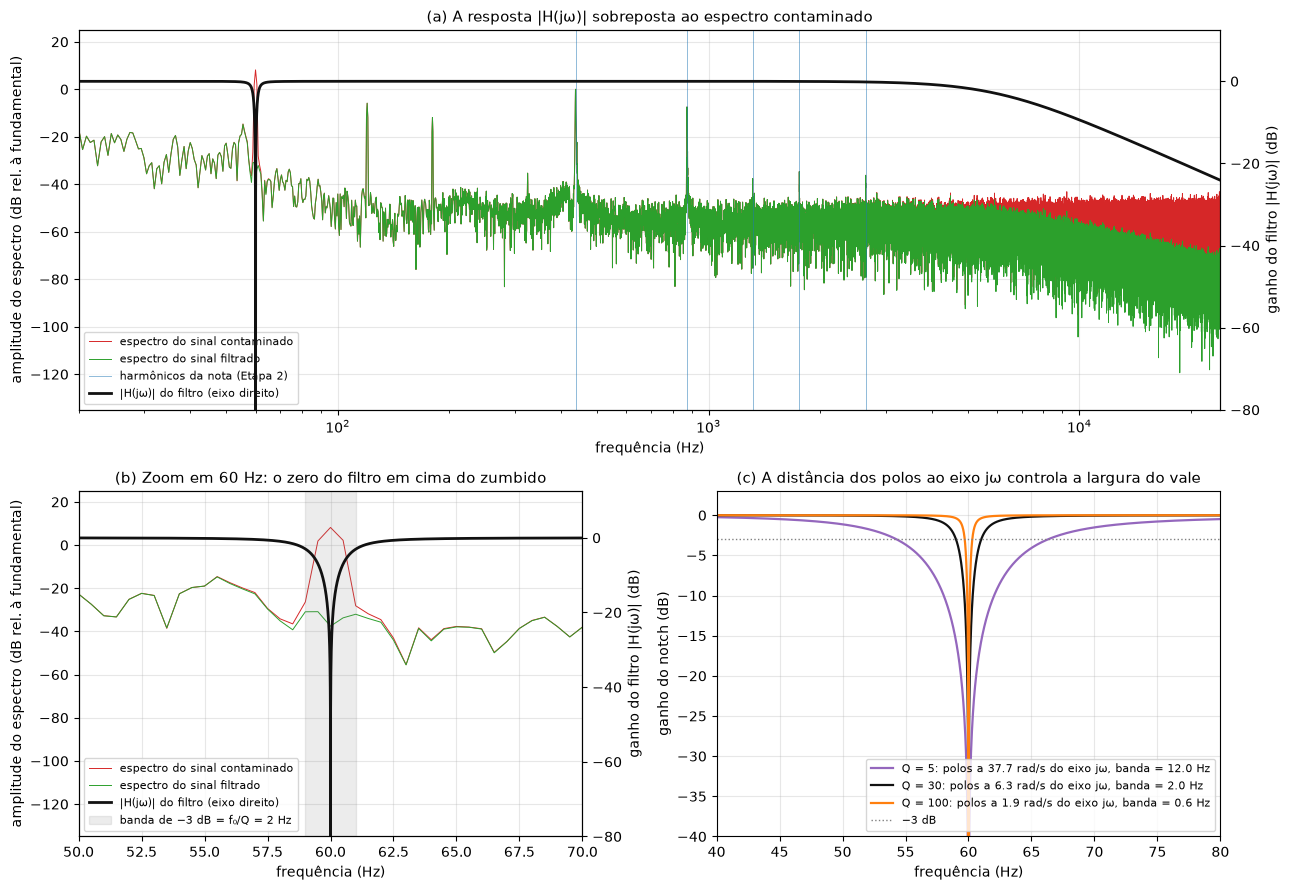

In [44]:
fig = plt.figure(figsize=(13, 9))
grade = fig.add_gridspec(2, 2, height_ratios=[1.1, 1])
painel_espectros(fig.add_subplot(grade[0, :]), (20, fs / 2), escala_log=True, marcar_harmonicos=True,
                 titulo="(a) A resposta |H(jω)| sobreposta ao espectro contaminado")
painel_espectros(fig.add_subplot(grade[1, 0]), (50, 70), escala_log=False, com_banda=True,
                 titulo="(b) Zoom em 60 Hz: o zero do filtro em cima do zumbido")
painel_efeito_de_Q(fig.add_subplot(grade[1, 1]))
salvar_fig(fig, "fig19_fechamento_polos_zeros_espectro.png")

**Fechamento: a mesma história contada em duas linguagens**

Cheguei ao ponto que, para mim, amarra o trabalho todo. Cada coisa que vi no espectro tem uma explicação no plano $s$.

**1. Os zeros em $\pm j\omega_0$ explicam o vale exato em 60 Hz.** O zero do notch está *em cima* do eixo $j\omega$, no ponto $s=j\,2\pi\cdot60$. Quando a frequência chega a 60 Hz, a distância até esse zero é nula, o numerador de $|H|$ zera e o ganho é exatamente 0 (primeira linha da tabela). No painel (b), o fundo do vale da curva preta cai bem em cima da linha do zumbido no espectro vermelho, e o espectro verde mostra a linha eliminada. Dá para dizer isso de três jeitos. Na linguagem da Etapa 2: "a raia de 60 Hz foi multiplicada por zero". Na da Etapa 4: "o sistema tem um zero em $s=j\omega_0$". Na da equação diferencial: a entrada $x=\sin\omega_0t$ satisfaz $x''+\omega_0^2x=0$, isto é, anula o lado direito da EDO do notch. As três frases dizem a mesma coisa.

**2. A distância dos polos ao eixo $j\omega$ controla a largura do vale.** Os polos ficam $\omega_0/2Q$ à esquerda dos zeros. Longe de 60 Hz, a distância de $j\omega$ até o polo e até o zero vizinho é praticamente igual: uma cancela a outra e o ganho fica em $\approx1$ (últimas linhas da tabela). Esse cancelamento só falha em uma vizinhança de $\omega_0$ cujo tamanho é parecido com a própria distância do polo ao eixo. Por isso a banda rejeitada é $B=2\cdot\frac{\omega_0}{2Q}=\frac{\omega_0}{Q}$ em rad/s, ou $f_0/Q=2$ Hz. Nas bordas (59 e 61 Hz) o ganho é $1/\sqrt2\approx0{,}707$ ($-3$ dB), como a tabela confirma. O painel (c) mostra o que acontece mudando $Q$: com os polos mais longe do eixo ($Q=5$) o vale tem 12 Hz de largura; com os polos colados no eixo ($Q=100$), 0,6 Hz. E a seção 4.4 mostrou o outro lado da mesma moeda: polo mais perto do eixo significa envoltória $e^{-\omega_0t/2Q}$ mais lenta. **Vale estreito na frequência e resposta longa no tempo são a mesma informação**, um único número (a parte real do polo) lido em dois domínios.

**3. Os harmônicos da nota ficam na região de ganho $\approx 1$ e são preservados.** No painel (a), as linhas azuis marcam os harmônicos que medi na Etapa 2. Todas caem no trecho plano da curva preta, entre o vale de 60 Hz e a queda do passa-baixas. No plano $s$, isso quer dizer pontos do eixo $j\omega$ que estão longe do par polo-zero do notch (onde os dois se cancelam) e bem "abaixo" dos polos do passa-baixas, que só começam a pesar quando $\omega$ se aproxima de $\omega_c$. É por isso que a fundamental passa com ganho 0,99999 (tabela) e o timbre não muda.

**4. O que sobrou também tem explicação.** Em 120 e 180 Hz o ganho é $\approx1$, porque não existe zero ali, e os harmônicos do zumbido atravessam o filtro. Foi o que vi no espectro filtrado e na SNR. O ruído branco abaixo de 6 kHz está na região de ganho 1 e passa. Acima, a curva preta cai e o espectro verde cai junto, com a mesma inclinação.

**Resumindo.** A série de Fourier me ensinou a enxergar um sinal como soma de senoides (Etapa 1). A FFT mediu essas senoides em um sinal real e mostrou quais eram música e quais eram interferência (Etapa 2). Filtrar foi multiplicar cada senoide por um número complexo $H(j\omega)$ e somar tudo de volta (Etapa 3). E a Transformada de Laplace mostrou que esse conjunto de números não é arbitrário: é a função de transferência de um circuito, definida por completo por dois zeros e quatro polos (Etapa 4). O vale que abri no espectro e os zeros que marquei no plano $s$ são a mesma coisa, descrita em duas linguagens.

<a id="conclusao"></a>
# Conclusão

| Etapa | Resultado principal |
|---|---|
| 1 | Onda quadrada: $b_n=4/(n\pi)$ para $n$ ímpar, conferido simbolicamente. O pico de Gibbs tende a 1,179 (8,95% do salto) e não desaparece, só se estreita. Parseval verificado. |
| 2 | Lá4 de violão: $f_0\approx437{,}6$ Hz medida contra 440 Hz teóricos ($-2{,}4$ Hz, cerca de $-9$ cents). Harmônicos 1, 2, 3, 4 e 6 detectados, com leve inarmonicidade; fundamental e 2º harmônico concentram mais de 90% da energia. Aliasing demonstrado em senoide de teste e no próprio sinal. |
| 3 | Contaminação sintética (zumbido de 60/120/180 Hz e ruído branco). Notch em 60 Hz com $Q=30$ mais Butterworth de 2ª ordem em 6 kHz, aplicados por multiplicação do espectro e FFT inversa. SNR de 2,9 dB para 12,1 dB (filtro causal) ou 15,5 dB (fase zero). Restaram os harmônicos do zumbido e o ruído dentro da faixa da música. |
| 4 | $H(s)$ obtida das equações diferenciais por Laplace. Zeros em $\pm j377$ rad/s, polos do notch em $-6{,}28\pm j376{,}9$ rad/s, polos do passa-baixas em $(-26{,}7\pm j26{,}7)\times10^3$ rad/s. Sistema estável. Bode simbólico e numérico coincidem. |

**O que ficou de aprendizado.** O que mais me marcou foi ver que as três ferramentas da disciplina falam do mesmo objeto. O filtro que desenhei como uma curva em cima do espectro é o mesmo que sai de uma equação diferencial, e os dois são resumidos por meia dúzia de pontos no plano $s$. Também aprendi a desconfiar dos números: a SNR do filtro causal parecia dizer que o passa-baixas tinha piorado o sinal, e só olhando o erro por faixa entendi que era efeito de um atraso mínimo, e não de ruído.

**Limitações e o que eu faria a seguir.** A contaminação é sintética e o zumbido está cravado em 60,000 Hz. Em uma gravação real a frequência da rede flutua e o zumbido tem mais harmônicos. Um filtro pente (notches em 60, 120, 180 Hz...) tiraria os harmônicos que sobraram. Já o ruído de banda larga dentro da faixa do sinal pede técnicas não lineares ou adaptativas, como a subtração espectral, que estão fora do escopo da disciplina. A nota que escolhi é curta e tem poucos harmônicos fortes; uma nota mais grave e sustentada daria um espectro mais rico. Por fim, analisei um único trecho de 1 s. Um espectrograma mostraria como cada harmônico decai ao longo do tempo.

**Fonte do áudio.** University of Iowa Electronic Music Studios, *Musical Instrument Samples* (Lawrence Fritts), arquivo `Guitar.mf.sulG.C4B4.mono.aif`. O acervo declara que as gravações podem ser baixadas e usadas em qualquer projeto, sem restrições. <https://theremin.music.uiowa.edu/MIS.html>

**Referências**

- OPPENHEIM, A. V.; WILLSKY, A. S. *Sinais e Sistemas*. 2. ed. Pearson, 2010.
- LATHI, B. P. *Sinais e Sistemas Lineares*. 2. ed. Bookman, 2007.
- KREYSZIG, E. *Matemática Superior para Engenharia*. 10. ed. LTC, 2019. (Séries de Fourier, Transformadas de Fourier e de Laplace.)
- Documentação do SciPy (`scipy.fft`, `scipy.signal`) e do SymPy (`laplace_transform`).